In [1]:
import json
import os
import time
import warnings
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

import graph_build as gb            # team module: the data as of t
import layer1_models as l1          # Layer 1 modelling code (Prep, make_model, fit_model, get_score)
import layer2_features as l2f       # Layer 2 variables: one function per typology

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
DATA_DIR, OUT, FZ1, FZ2 = "student_bundle", "results", "results/layer1_frozen", "results/layer2_frozen"
os.makedirs(FZ2, exist_ok=True)
N_JOBS = 2

# periods and cut-offs of dossier 8.1 (frozen in Layer 1)
config_L1 = json.load(open(f"{FZ1}/config.json"))
CUTOFFS = [pd.Timestamp(c) for c in config_L1["cutoffs"]]
T_TRAIN, T_VAL, T_TEST = CUTOFFS
PERIOD_ORDER = list(config_L1["periods"])

# cases, their members and the period in which each case emerges
labels = pd.read_csv(os.path.join(DATA_DIR, "labelled_cases_TRAINING_SET.csv"))
labels["members"] = labels.member_record_ids.str.split("|")
case_tab = pd.read_csv(f"{FZ1}/case_periods.csv")
case_mem = {c.case_id: set(c.members) for c in labels.itertuples()}
case_typ = dict(zip(labels.case_id, labels.typology_tags))
case_period = dict(zip(case_tab.case_id, case_tab.period))
CASES_IN = {p: [c for c in case_tab.case_id if case_period[c] == p] for p in PERIOD_ORDER}

# Layer 1 inputs: as-of-t record variables, the variables Layer 1 selected in each training fit, its scores
FEATS_L1 = config_L1["modelling_features"]
L1 = {t: pd.read_csv(f"{FZ1}/features_L1_asof_{t.date()}.csv").set_index("record_id")[FEATS_L1] for t in CUTOFFS}
L1_SEL = {(d["seed"], d["period"], d["fold"]): d["variables"]
          for d in json.load(open(f"{FZ1}/fold_selected_variables.json")) if d["version"] == "full"}
L1_OOF = pd.read_csv(f"{FZ1}/oof_scores.csv").query("version == 'full'")
SEEDS = sorted({k[0] for k in L1_SEL})

# groups for grouped CV: members of one case (and of cases sharing members) form one group
all_pos = set().union(*case_mem.values())
parent = {}


def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


for ms in labels.members:
    for m in ms[1:]:
        parent[find(m)] = find(ms[0])
GROUP = {r: ("G_" + find(r)) if r in all_pos else ("N_" + r) for r in L1[T_TEST].index}


def members(cases):
    return set().union(*[case_mem[c] for c in cases]) if len(cases) else set()


def case_weights(rids, y, cases):
    """AP_case weights: every case has the same total weight, whatever its size"""
    raw = defaultdict(float)
    for c in cases:
        for m in case_mem[c]:
            raw[m] += 1.0 / len(case_mem[c])
    w = np.ones(len(rids))
    pos = y == 1
    r_ = np.array([raw.get(r, 0.0) for r in rids])
    w[pos] = r_[pos] * pos.sum() / r_[pos].sum()
    return w


def make_set(t, cases, earlier=(), name=""):
    """records known at t; members of earlier cases are removed (already found and reviewed)"""
    idx = L1[t].index
    rids = idx[~idx.isin(members(list(earlier)) - members(list(cases)))].to_numpy()
    y = np.isin(rids, list(members(list(cases)))).astype(int)
    return dict(name=name, t=t, rid=rids, y=y, g=np.array([GROUP[r] for r in rids]), w=case_weights(rids, y, cases),
                cases=list(cases))


TR_TRAIN = make_set(T_TRAIN, CASES_IN["TRAINING"], name="TR_TRAIN")
EV_VAL = make_set(T_VAL, CASES_IN["VALIDATION"], CASES_IN["TRAINING"], name="EV_VAL")
EV_TEST = make_set(T_TEST, CASES_IN["TEST"], CASES_IN["TRAINING"] + CASES_IN["VALIDATION"], name="EV_TEST")
EVAL_SET = {"TRAINING_cv": TR_TRAIN, "VALIDATION": EV_VAL, "TEST": EV_TEST}

split = pd.DataFrame([
    dict(set=s_["name"], role=role, **{"as of": str(s_["t"].date()), "labels from": lab, "records": len(s_["y"]),
         "case members": int(s_["y"].sum()), "cases": len(s_["cases"]), "random AP": round(s_["y"].mean(), 3)})
    for s_, role, lab in [(TR_TRAIN, "TRAINING: the only training set (in-period grouped 5-fold CV = TRAINING_cv)", "TRAINING"),
                          (EV_VAL, "VALIDATION: scored by the trained model, used to choose the model", "VALIDATION"),
                          (EV_TEST, "TEST: scored by the same trained model, the result", "TEST")]]).set_index("set")
display(split)
print({p: ", ".join(CASES_IN[p]) for p in PERIOD_ORDER})

,role,as of,labels from,records,case members,cases,random AP
set,,,,,,,
TR_TRAIN,TRAINING: the only training set (in-period grouped 5-fold CV = TRAINING_cv),2024-06-30,TRAINING,797,70,16,0.088
EV_VAL,"VALIDATION: scored by the trained model, used to choose the model",2025-06-30,VALIDATION,824,23,7,0.028
EV_TEST,"TEST: scored by the same trained model, the result",2026-06-30,TEST,909,66,10,0.073


{'TRAINING': 'CASE-0001, CASE-0002, CASE-0004, CASE-0005, CASE-0009, CASE-0015, CASE-0018, CASE-0020, CASE-0021, CASE-0022, CASE-0023, CASE-0024, CASE-0027, CASE-0028, CASE-0029, CASE-0030', 'VALIDATION': 'CASE-0003, CASE-0011, CASE-0013, CASE-0016, CASE-0019, CASE-0025, CASE-0026', 'TEST': 'CASE-0006, CASE-0007, CASE-0008, CASE-0010, CASE-0012, CASE-0014, CASE-0017, CASE-0031, CASE-0032, CASE-0033'}


# Layer 2: relationship logic

## 1. Data split

The split follows the dossier's experimental design. Every choice below comes from it:

| choice | dossier |
|---|---|
| **Three periods by emergence date:** TRAINING (cases emerging up to 2024-06-30), VALIDATION (2024-07-01 – 2025-06-30), TEST (2025-07-01 – 2026-06-30). A case sits entirely in one period. | §8.1 "Time periods defined by the sponsor"; App. B "Case partition: no planted case spans train, validation, and test" |
| **Data as of the cut-off:** each period is described by the data known at its end (2024-06-30, 2025-06-30, 2026-06-30): valid **and** observed by t. | §8.1 "A graph as of time t should contain only relationships observed by t and valid at t"; §8.2 "future relationships leaking into historic features" |
| **Three sets, trained once:** every model is fitted once on the TRAINING set (`TR_TRAIN`, the TRAINING period as of 2024-06-30). The same fitted model scores VALIDATION and TEST; VALIDATION labels are only used to choose between models, never to train. | §8.1 (three periods); §9 (the test period is scored blind) |
| **Earlier cases removed** from a later evaluation set: by then they were already found and reviewed. | follows from the time order of §8.1 |
| **TRAINING is scored by grouped 5-fold CV** inside `TR_TRAIN` (only to give TRAINING cases a score); all members of one case stay in the same fold. | App. B "Case partition"; the same folds as Layer 1 |
| **VALIDATION chooses the model, TEST is the result.** | §8.1 ("validation-period labels are released mid-project", the test period is scored blind) |
| **Metrics:** AP, case-balanced AP, P@k and R@k for review queues k = 10, 25, 50, 100; a case is *found* @k when the top k, grouped into predicted cases, contain one with IoU > 0.5 against it (below); `case precision @k`. | §9 "Precision@k and Recall@k for review queues of 10 to 100, Average Precision … member recall" |

**How a case is found (IoU rule).** The models score single vendors; a labelled case is a group of vendors. To compare the two, the top k vendors are grouped into **predicted cases** (`predicted_cases`):
- two vendors are linked when they are the same resolved entity, or share a relation that carries a typology firing on both (signal ≥ 0.3): an address for `SHARED_ADDRESS`, an owner for `COMMON_BENEFICIAL_OWNER`, a sponsor for `SPONSOR_CONCENTRATION`, the onboarding window for `RAPID_ONBOARDING_LINKED`, … (hub values removed, as in Layer 2);
- two vendors that share **two or more** rare relations (address, owner, phone, e-mail domain, healthcare institution) are linked as well. A single shared value without typology support does not link: sponsor and approver links are about as common outside cases as inside (lift 1.0 and 1.4, section 3), and one shared institution would attach a bridge vendor to whichever group it touches;
- each linked group is split into Louvain communities (edge weight = number of shared relation kinds), so one weak link cannot chain two cases together;
- a vendor linked to no other top-k vendor is a one-vendor predicted case.

This rule was chosen in two rounds, each time by the cases found on TRAINING_cv and VALIDATION only (summed over k and the three Layer 2 models); TEST was not used for the choice. Round 1 compared six rules (rare relations only; + sponsor; + two weak kinds together; + sponsor with window or approver; typology-aware; all relations), each with and without Louvain. Round 2 refined the typology-aware rule: requiring typology support also for a single rare relation, heavier rare-link weights, and Louvain resolution 1 / 1.5 / 2; only the first helped. Round 2 was prompted by TEST misses (single-vendor cases merged into larger groups), but the same problem occurs in TRAINING (CASE-0029) and the choice was made on TRAINING_cv and VALIDATION.

A labelled case is **found @k** when some predicted case has IoU = |case ∩ predicted| / |case ∪ predicted| > 0.5 with it, in at least 3 of the 5 seeds. This is stricter than member recall: the members must be in the top k **and** be grouped together without too many other vendors. `case precision @k` is the share of predicted cases that match a labelled case with IoU > 0.5.

The split, the as-of-t Layer 1 variables, the cases and the training-once protocol are the same as in Layer 1 (`results/layer1_frozen/`), so Layer 1 and Layer 2 are compared on exactly the same records.

## 2. Layer 2 variables

The dossier lists 13 typologies as graph hypotheses (§6). The practice labels use 14 tags, because approver concentration and sponsor–approver coupling (§2.4) are tagged separately. Every Layer 2 variable belongs to one typology.
- **Variables** are the candidate features the dossier names for that typology (§2.2–§2.13, §3.6–§3.9, Appendix A), computed in `layer2_features.py` on the data as of each cut-off.
- **Signal**: each typology also gets one signal `s_<TYPOLOGY>` ∈ [0, 1]. It measures how rare it is to meet the pattern this strongly, as normalised self-information (Shannon 1948): a pattern held by one vendor scores 1.
- **Counting unit**:
  - Where group size is itself the evidence (common owner, dense cluster, linked onboarding, ownership + operations), a group of m vendors counts once (dossier §6.1: the review unit is a case).
  - Where large groups are usually benign hubs (addresses, sponsors, approvers), every vendor counts (§2.2–2.4).

| # | typology | what it is (dossier) | variables |
|---|---|---|---|
| T1 | `SHARED_ADDRESS` | several vendors at one rare, non-agent address (§2.2) | `sa_*`, `lk_aa_address_max` |
| T2 | `SPONSOR_CONCENTRATION` | one employee sponsors an unusual burst of vendors compared with role peers (§2.3) | `sc_*`, `lk_aa_sponsor_max` |
| T3 | `APPROVER_CONCENTRATION` | one approver handles far more than role peers, partly above its authority (§2.4) | `ac_*`, `lk_aa_approver_max` |
| T4 | `SPONSOR_APPROVER_COUPLING` | a sponsor routes almost all approvals to one approver although others are available (§2.4, §3.7) | `pc_*` |
| T5 | `DENSE_MULTI_RELATION_CLUSTER` | a group shares several rare relations at once (§2.5) | `dc_*`, Jaccard / Adamic–Adar `lk_*` |
| T6 | `RAPID_ONBOARDING_LINKED` | a linked group is onboarded within 28 days, faster than the country's usual rate (§2.6) | `ro_*` |
| T7 | `BRIDGE_ENTITY` | a vendor connects otherwise separate healthcare-institution communities (§2.7, §3.8) | `br_*`, `lk_aa_institution_max` |
| T8 | `GEOGRAPHY_LINKED_CONCENTRATION` | a new pocket of intermediaries in one market (§2.8) | `gc_*` |
| T9 | `ACTIVITY_TIMING_CONCENTRATION` | vendors of one sponsor have payment spikes in the same month (§2.6) | `at_*` |
| T10 | `COMMON_BENEFICIAL_OWNER` | nominally separate, undeclared vendors converge on one natural person (§2.9) | `co_*`, `lk_aa_owner_max` |
| T11 | `LAYERED_COMPLEX_OWNERSHIP` | deep ownership chain across jurisdictions, trusts or nominees (§2.10) | `lo_*` |
| T12 | `OWNERSHIP_OPERATIONAL_OVERLAP` | co-owned vendors that also share operations, e.g. an expert owning an agency engaged by the same sponsor (§2.11) | `oo_*` |
| T13 | `OPAQUE_JURISDICTION_ROUTING` | ownership path through an off-list, sanctioned or low-transparency jurisdiction, or an undisclosed PEP (§2.12) | `oj_*` |
| T14 | `OWNERSHIP_CHANGE_STRUCTURAL_SHIFT` | an ownership change followed within 90 days by a change in the vendor's relations (§2.13, §3.9) | `oc_*` |

Every threshold has a source:

| parameter | value | source |
|---|---|---|
| `MIN_GROUP` | 3 entities | dossier §3.6 ("at least three active vendors at a rare address") |
| `DENSE_KINDS` | 3 kinds | dossier §3.6 (address + sponsor + owner) |
| `W_ONBOARD` / `W_SPONSOR` / `W_SHIFT` | 28 / 60 / 90 days | dossier App. C / §3.9 / §3.9 |
| `DEPTH_MIN` | 3 levels | dossier §2.10 |
| `MIN_COUNT` | 5 | Cochran (1954) |
| `Z_OUT` | 3.5 | Iglewicz & Hoaglin (1993) |
| `HHI_HIGH`, `MIN_POOL` | 0.25, 5 | DOJ/FTC merger guidelines (2010); with ≤ 4 approvers HHI ≥ 0.25 holds trivially |
| `TUKEY_K` | 3 × IQR | Tukey (1977): shared values beyond the far-out fence are hubs, not links |
| `W_SYNC`, `W_MARKET` | ±1 month, 365 days | monthly data grain (§1); annual context cycle |
| `NAME_SIM` | 0.70 | team entity resolution (`graph_build`) |

**Variable selection** (next cell), on training rows only:
- For every variable, how well it separates case members from other vendors: AUC with a 95 % CI.
- Members of one case are not independent, so the CI comes from a bootstrap that resamples cases and non-case vendors (cluster bootstrap).
- A variable is **significant** if the lower CI bound is above 0.5.
- It is computed on `TR_TRAIN`, the training set (TRAINING cases only).

In [2]:
t0 = time.time()
L2, CTX = {}, {}
for t_ in CUTOFFS:
    L2[t_], CTX[t_] = l2f.build_layer2(t_, DATA_DIR)
    g_ = CTX[t_]["graph"]
    assert not (g_.edges.valid_from.gt(t_) | g_.edges.valid_to.gt(t_) | g_.edges.observed_at.gt(t_)).any(), "future data"
    assert set(L2[t_].index) == set(L1[t_].index)
    L2[t_] = L2[t_].loc[L1[t_].index]
    L2[t_].reset_index().to_csv(f"{FZ2}/features_L2_asof_{t_.date()}.csv", index=False)
    pd.DataFrame([(a, b, "|".join(sorted(k))) for (a, b), k in CTX[t_]["pairs"].items()],
                 columns=["entity_a", "entity_b", "relation_kinds"]).to_csv(f"{FZ2}/relation_pairs_asof_{t_.date()}.csv", index=False)
GROUPS = l2f.groups_of(L2[T_TEST].columns)
VARS14 = [v for k in l2f.TYPOLOGIES for v in GROUPS[k]]
print(f"Layer 2 built at 3 cut-offs in {(time.time() - t0) / 60:.1f} min: {len(VARS14)} variables in 14 typologies")


def cluster_bootstrap_auc(x, TR, n_boot=1000, seed=0):
    """AUC of x for case members vs other records, 95 % CI resampling groups (a case = one group)"""
    y, g = TR["y"], pd.Series(TR["g"])
    idx_of = g.groupby(g).indices
    pos_g = [k for k in idx_of if k.startswith("G_")]
    neg_g = [k for k in idx_of if not k.startswith("G_")]
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        rows = np.concatenate([idx_of[k] for k in rng.choice(pos_g, len(pos_g))] +
                              [idx_of[k] for k in rng.choice(neg_g, len(neg_g))])
        boots.append(roc_auc_score(y[rows], x[rows]))
    return roc_auc_score(y, x), *np.percentile(boots, [2.5, 97.5])


rows = []
for v in VARS14:
    r = dict(variable=v, typology=l2f.typology_of(v))
    for nm, TR in [("TR_TRAIN", TR_TRAIN)]:
        x = L2[TR["t"]].loc[TR["rid"], v].astype(float).fillna(0).to_numpy()
        if np.unique(x).size < 2:
            r[f"AUC {nm}"], r[f"95% CI {nm}"], r[f"significant {nm}"] = np.nan, "constant", False
            continue
        auc, lo, hi = cluster_bootstrap_auc(x, TR)
        r[f"AUC {nm}"], r[f"95% CI {nm}"], r[f"significant {nm}"] = round(auc, 3), f"[{lo:.2f}, {hi:.2f}]", lo > 0.5
    rows.append(r)
SIG = pd.DataFrame(rows).set_index("variable").sort_values(["significant TR_TRAIN", "AUC TR_TRAIN"], ascending=False)
SIG.to_csv(f"{OUT}/L2_variable_significance.csv")
print(f"significant variables on TR_TRAIN: {int(SIG['significant TR_TRAIN'].sum())} / {len(SIG)}")
display(SIG)
by_typ = SIG.groupby("typology").agg(variables=("AUC TR_TRAIN", "size"), significant=("significant TR_TRAIN", "sum"),
                                     best_AUC=("AUC TR_TRAIN", "max"))
by_typ.insert(0, "TRAINING cases with tag", [sum(k in case_typ[c].split("|") for c in TR_TRAIN["cases"]) for k in by_typ.index])
display(by_typ.reindex(l2f.TYPOLOGIES))

Layer 2 built at 3 cut-offs in 0.4 min: 87 variables in 14 typologies


significant variables on TR_TRAIN: 27 / 87


,typology,AUC TR_TRAIN,95% CI TR_TRAIN,significant TR_TRAIN
variable,,,,
ro_burst_ratio,RAPID_ONBOARDING_LINKED,0.855,"[0.74, 0.93]",True
dc_max_shared_types,DENSE_MULTI_RELATION_CLUSTER,0.852,"[0.78, 0.90]",True
dc_kind_entropy,DENSE_MULTI_RELATION_CLUSTER,0.812,"[0.74, 0.89]",True
ro_n_linked_in_window,RAPID_ONBOARDING_LINKED,0.750,"[0.56, 0.86]",True
dc_n_partners_3types,DENSE_MULTI_RELATION_CLUSTER,0.748,"[0.64, 0.85]",True
...,...,...,...,...
ro_country_prior_rate,RAPID_ONBOARDING_LINKED,0.322,"[0.20, 0.42]",False
pc_pair_pmi,SPONSOR_APPROVER_COUPLING,0.318,"[0.21, 0.47]",False
s_BRIDGE_ENTITY,BRIDGE_ENTITY,NaN,constant,False


,TRAINING cases with tag,variables,significant,best_AUC
typology,,,,
SHARED_ADDRESS,2,7,0,0.632
SPONSOR_CONCENTRATION,2,7,0,0.685
APPROVER_CONCENTRATION,0,6,1,0.678
SPONSOR_APPROVER_COUPLING,0,5,1,0.635
DENSE_MULTI_RELATION_CLUSTER,1,10,8,0.852
RAPID_ONBOARDING_LINKED,0,7,3,0.855
BRIDGE_ENTITY,0,6,3,0.587
GEOGRAPHY_LINKED_CONCENTRATION,1,6,0,0.597
ACTIVITY_TIMING_CONCENTRATION,1,4,0,0.518


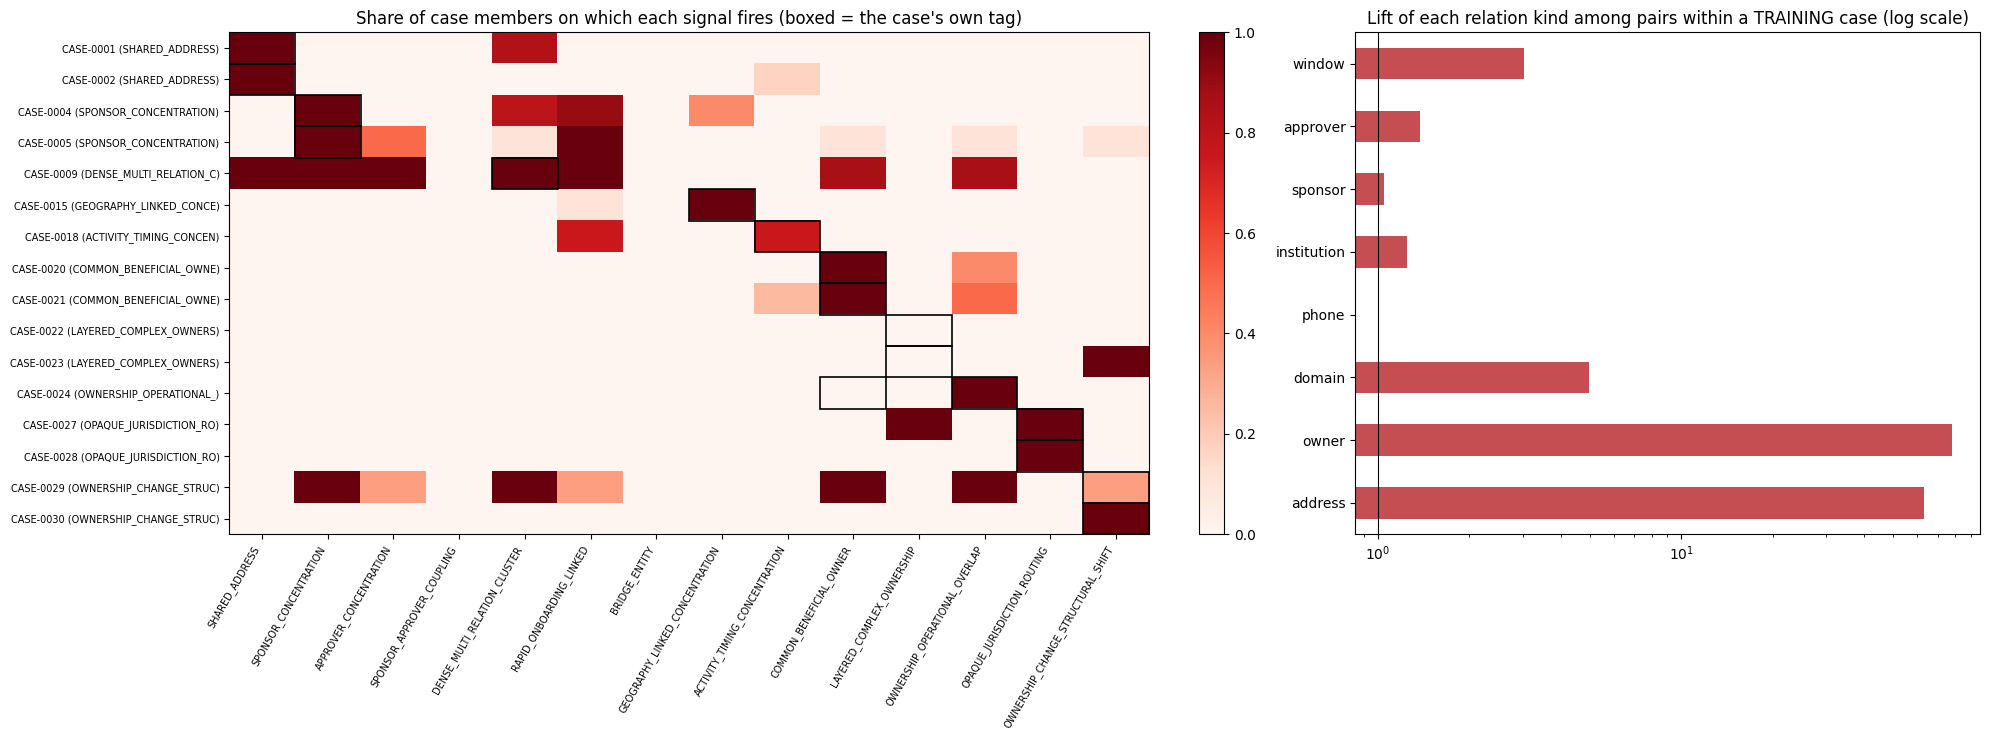

cases on which no member fires its own typology signal: ['CASE-0022', 'CASE-0023']

Candidate patterns at 2026-06-30 (label-free; only training cases are shown)


,definition,vendors,training-case members,median strongest of the 14 signals
candidate,,,,
PUBLIC_INSTITUTION_EXPERT_CLUSTER,"≥ 2 other experts at the same public institution, engaged by the same sponsor",6,0,0.64
FMV_CAP_BREACH,expert paid above the annual fair-market-value cap in force,3,0,0.00
PAYMENT_AFTER_TERMINATION,paid in a month after the termination month,1,0,0.00
SPLIT_ENGAGEMENTS,"≥ 2 small engagements of one vendor and sponsor within 28 days, together above the band-1 limit",4,0,0.17
UNDECLARED_SHARED_CONTACT,phone or own e-mail domain shared outside the declared group,105,11,0.31
REONBOARDED_AFTER_TERMINATION,same tax id or phone as a record terminated before,21,1,0.34
SELF_APPROVAL,sponsor approves its own engagement,50,7,0.34


Groups of entities sharing >= 2 relation kinds, by what explains them


components  entities  largest
explained_by   signature                                                           
14 typologies  approver+sponsor                               22       395      127
nothing        approver+sponsor                               19        45        4
14 typologies  sponsor+window                                 11        36       10
               approver+window                                 4        10        4
nothing        sponsor+window                                  4         8        2
14 typologies  domain+owner                                    2         4        2
               institution+sponsor                             2        12       10
               address+approver                                1         7        7
               address+approver+owner+sponsor+window           1        13       13
               approver+owner+sponsor                          1         4        4
               domain+sponsor                                  1        16       16
               address+owner+sponsor                           1         3        3
               address+sponsor                                 1         5        5
               owner+sponsor                                   1         2        2
declared group domain+phone                                    1         2        2

In [3]:
SIG14 = [f"s_{k}" for k in l2f.TYPOLOGIES]
TRAIN_CASES = CASES_IN["TRAINING"]
CUT_OF = {"TRAINING": T_TRAIN, "VALIDATION": T_VAL, "TEST": T_TEST}

# (1) which typology signal fires on the members of which training case (each case at its own cut-off)
heat = pd.DataFrame({c: (L2[CUT_OF[case_period[c]]].loc[list(case_mem[c]), SIG14] > 0).mean() for c in TRAIN_CASES}).T
heat.columns = [k.replace("s_", "") for k in heat.columns]
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
im = axes[0].imshow(heat.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(heat.columns)), heat.columns, rotation=60, ha="right", fontsize=7)
axes[0].set_yticks(range(len(heat)), [f"{c} ({case_typ[c].split('|')[0][:22]})" for c in heat.index], fontsize=7)
for i, c in enumerate(heat.index):
    for k in case_typ[c].split("|"):
        if k in heat.columns:
            axes[0].add_patch(plt.Rectangle((list(heat.columns).index(k) - 0.5, i - 0.5), 1, 1, fill=False, ec="k", lw=1.2))
axes[0].set_title("Share of case members on which each signal fires (boxed = the case's own tag)")
plt.colorbar(im, ax=axes[0], fraction=0.03)

# (2) link metrics: which relation kinds connect members of the same training case (TR_TRAIN, 2024-06-30)
re_of = CTX[T_TRAIN]["T"]["tp"].re
within = {tuple(sorted(p)) for c in CASES_IN["TRAINING"]
          for p in combinations(sorted(set(re_of.reindex(list(case_mem[c])).dropna())), 2)}
pairs_tr = CTX[T_TRAIN]["pairs"]
KINDS = ["address", "owner", "domain", "phone", "institution", "sponsor", "approver", "window"]
lift = {}
for kd in KINDS:
    w_ = np.mean([kd in k for p, k in pairs_tr.items() if p in within])
    o_ = np.mean([kd in k for p, k in pairs_tr.items() if p not in within])
    lift[kd] = w_ / o_ if o_ > 0 else np.nan
pd.Series(lift).plot.barh(ax=axes[1], color="#C44E52", logx=True)
axes[1].axvline(1, c="k", lw=0.8)
axes[1].set_title("Lift of each relation kind among pairs within a TRAINING case (log scale)")
plt.tight_layout(); plt.savefig(f"{OUT}/L2_eda.png", dpi=130); plt.show()
print("cases on which no member fires its own typology signal:",
      [c for c in TRAIN_CASES if all(heat.loc[c].get(k, 0) == 0 for k in case_typ[c].split("|"))])

# (3) patterns outside the 14 typologies, searched without labels at the latest cut-off
F_s, L1_s, T_s = L2[T_TEST], L1[T_TEST], CTX[T_TEST]["T"]
S14 = F_s[SIG14].max(axis=1)
train_member = members(TRAIN_CASES)
CANDIDATES = {
    "PUBLIC_INSTITUTION_EXPERT_CLUSTER": ("≥ 2 other experts at the same public institution, engaged by the same sponsor",
                                          F_s.nx_inst_expert_cluster_public >= l2f.MIN_GROUP - 1),
    "FMV_CAP_BREACH": ("expert paid above the annual fair-market-value cap in force", L1_s.max_fmv_cap_ratio > 1),
    "PAYMENT_AFTER_TERMINATION": ("paid in a month after the termination month", L1_s.n_months_paid_after_term >= 1),
    "SPLIT_ENGAGEMENTS": ("≥ 2 small engagements of one vendor and sponsor within 28 days, together above the band-1 limit",
                          F_s.nx_split_engagements >= 2),
    "UNDECLARED_SHARED_CONTACT": ("phone or own e-mail domain shared outside the declared group",
                                  F_s.nx_contact_shared_undeclared >= 1),
    "REONBOARDED_AFTER_TERMINATION": ("same tax id or phone as a record terminated before", F_s.nx_reonboarded_after_termination >= 1),
    "SELF_APPROVAL": ("sponsor approves its own engagement", L1_s.n_approver_is_sponsor >= 1),
}
cand = pd.DataFrame([dict(candidate=n, definition=d, vendors=int(m.sum()),
                          **{"training-case members": int(sum(r in train_member for r in m[m].index)),
                             "median strongest of the 14 signals": round(float(S14[m].median()), 2) if m.any() else np.nan})
                     for n, (d, m) in CANDIDATES.items()]).set_index("candidate")
print("\nCandidate patterns at 2026-06-30 (label-free; only training cases are shown)")
display(cand)

# residual structure: groups of entities sharing >= 2 relation kinds that no typology signal explains
pairs_s, tp_s = CTX[T_TEST]["pairs"], T_s["tp"]
G2 = nx.Graph([p for p, k in pairs_s.items() if len(k) >= 2])
s_re = S14.groupby(tp_s.re).max()
res_rows = []
for comp in nx.connected_components(G2):
    kinds = pd.Series(["+".join(sorted(pairs_s[tuple(sorted(e))])) for e in G2.subgraph(comp).edges]).value_counts()
    recs = tp_s.index[tp_s.re.isin(comp)]
    grp = tp_s.loc[recs].group
    res_rows.append(dict(size=len(comp), signature=kinds.index[0], max_s14=float(s_re.reindex(list(comp)).max()),
                         explained_by="declared group" if grp.notna().all() and grp.nunique() == 1
                         else ("14 typologies" if s_re.reindex(list(comp)).max() >= 0.3 else "nothing")))
resid = pd.DataFrame(res_rows).groupby(["explained_by", "signature"]).agg(components=("size", "size"),
                                                                         entities=("size", "sum"), largest=("size", "max"))
print("Groups of entities sharing >= 2 relation kinds, by what explains them")
display(resid.sort_values("components", ascending=False).head(15))

In [4]:
inst_ = pd.read_csv(os.path.join(DATA_DIR, "healthcare_institutions.csv")).set_index("institution_id")
pay_m = T_s["pay"].assign(m=lambda d: d.month.dt.to_period("M")).groupby(["record_id", "m"]).amount_usd.sum().unstack().fillna(0)

ids = CANDIDATES["PUBLIC_INSTITUTION_EXPERT_CLUSTER"][1]
ids = ids[ids].index
aff_ = T_s["inst"][T_s["inst"].record_id.isin(ids) & (T_s["inst"].link_type == "AFFILIATED_WITH")]
detail = aff_.merge(T_s["tp"][["expert_type", "onboarding_date"]], left_on="record_id", right_index=True)
detail = detail.join(inst_[["inst_type", "country", "public_sector"]], on="institution")
detail["sponsors"] = detail.record_id.map(T_s["eng"].dropna(subset=["sponsor"]).groupby("record_id").sponsor.agg(
    lambda s: "|".join(sorted(set(s)))))
detail["peak_month"] = detail.record_id.map(pay_m.idxmax(axis=1).astype(str))
detail["peak / median month"] = detail.record_id.map((pay_m.max(axis=1) / pay_m.replace(0, np.nan).median(axis=1)).round(1))
print("PUBLIC_INSTITUTION_EXPERT_CLUSTER")
display(detail[["record_id", "institution", "inst_type", "country", "public_sector", "expert_type", "onboarding_date",
                "sponsors", "peak_month", "peak / median month"]])

ids = CANDIDATES["FMV_CAP_BREACH"][1]
print("FMV_CAP_BREACH")
display(L1_s.loc[ids[ids].index, ["max_fmv_cap_ratio", "n_pay_months"]].join(T_s["tp"][["expert_type", "country", "onboarding_date"]]))

ids = CANDIDATES["PAYMENT_AFTER_TERMINATION"][1]
print("PAYMENT_AFTER_TERMINATION")
display(L1_s.loc[ids[ids].index, ["n_months_paid_after_term"]].join(
    T_s["tp"][["party_type", "country", "onboarding_date", "terminated_date"]]))

ids = CANDIDATES["SPLIT_ENGAGEMENTS"][1]
print("SPLIT_ENGAGEMENTS")
display(F_s.loc[ids[ids].index, ["nx_split_engagements"]].join(T_s["tp"][["party_type", "country"]]))

contact = T_s["contact"].assign(re=lambda d: d.record_id.map(T_s["tp"].re))
shared = contact[contact.record_id.isin(CANDIDATES["UNDECLARED_SHARED_CONTACT"][1].pipe(lambda m: m[m].index))]
names = T_s["tp"].legal_name
matcher = gb.NameMatcher([gb.name_tokens(n) for n in names])
sim = [l2f.name_similarity(matcher, names[a], names[b])
       for v, d in shared.groupby("value") for a, b in combinations(sorted(d.record_id), 2)]
print(f"UNDECLARED_SHARED_CONTACT: name similarity of the vendor pairs sharing a phone / domain: "
      f"median {np.median(sim):.2f}, share ≥ {l2f.NAME_SIM}: {np.mean(np.array(sim) >= l2f.NAME_SIM):.0%}")

ap_ = pd.read_csv(os.path.join(DATA_DIR, "tp_engagement_approvals.csv")).merge(
    pd.read_csv(os.path.join(DATA_DIR, "tp_engagements.csv"))[["engagement_id", "sponsor_employee_id"]], on="engagement_id")
self_ = ap_[(ap_.approval_type == "financial") & (ap_.approver_employee_id == ap_.sponsor_employee_id)]
roles_ = pd.read_csv(os.path.join(DATA_DIR, "employee_roles.csv")).drop_duplicates("employee_id").set_index("employee_id").role
print("SELF_APPROVAL: role of the employees approving their own engagements:",
      self_.approver_employee_id.map(roles_).value_counts().to_dict())

PUBLIC_INSTITUTION_EXPERT_CLUSTER


,record_id,institution,inst_type,country,public_sector,expert_type,onboarding_date,sponsors,peak_month,peak / median month
5506,TP-95184614,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-06-21,EMP-87A0ECFB,2026-04,2.2
9346,TP-2A796C56,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-03-26,EMP-87A0ECFB,2026-04,5.2
11029,TP-BCC685BD,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-02-09,EMP-87A0ECFB,2026-04,6.1
17669,TP-3967C884,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-05-22,EMP-87A0ECFB,2026-04,3.0
18994,TP-C6CDBD3A,HCO-9920B679,hospital,VN,True,hcp_consultant,2024-12-29,EMP-87A0ECFB,2026-04,4.9
19068,TP-7A4B5571,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-08-28,EMP-87A0ECFB,2026-04,5.7


FMV_CAP_BREACH


,max_fmv_cap_ratio,n_pay_months,expert_type,country,onboarding_date
record_id,,,,,
TP-7CB3B5CE,2.776162,24.0,investigator_kol,TW,2010-03-02
TP-2AD5101E,1.241995,33.0,investigator_kol,CA,2023-10-13
TP-60212374,1.155575,26.0,investigator_kol,US,2023-12-12


PAYMENT_AFTER_TERMINATION


,n_months_paid_after_term,party_type,country,onboarding_date,terminated_date
record_id,,,,,
TP-33FC40CA,1.0,organization,DE,2020-07-20,2025-01-25


SPLIT_ENGAGEMENTS


,nx_split_engagements,party_type,country
record_id,,,
TP-82B3D29F,2.0,organization,DE
TP-744FAEAE,2.0,organization,JP
TP-5FFCFBAD,2.0,organization,US
TP-8350BEF1,2.0,organization,MA


UNDECLARED_SHARED_CONTACT: name similarity of the vendor pairs sharing a phone / domain: median 0.00, share ≥ 0.7: 9%
SELF_APPROVAL: role of the employees approving their own engagements: {'market_gm': 56}


## 3. New typologies

### 3.1 EDA and seven candidate patterns

**What the EDA shows.**
- **The 14 detectors fire on their own cases.** The heat map has a dark box in almost every row: the members of a TRAINING case trigger the signal of their own tag. The exceptions are CASE-0022 and CASE-0023, single-vendor layered-ownership cases whose chains do not reach `DEPTH_MIN` at 2024-06-30.
- **Shared rare relations link case members; shared employees do not.** Pairs inside a TRAINING case share an address or an owner far more often than other pairs (lift 63 and 78). Sponsor and approver links are hardly more common inside cases than outside (lift 1.0 and 1.4); the onboarding window is in between (3.0).

**Seven candidate patterns outside the 14** (searched without labels at 2026-06-30, details in the previous cell). Here they are only described; which of them become typologies is decided by the ablation (3.2) and the scorecard (3.3).

| candidate | what the previous cell shows |
|---|---|
| `PUBLIC_INSTITUTION_EXPERT_CLUSTER`: ≥ 3 individual experts at the same public-sector institution, engaged by the same sponsor | 6 HCP consultants at one public hospital in VN, one sponsor, onboarded within 8 months, all with their peak payment month in 2026-04 (2–6 × their median month). No address, owner, phone or domain links them; only the institution and the sponsor do. |
| `FMV_CAP_BREACH`: an expert paid above the annual fair-market-value cap in force | 3 investigators (TW, CA, US), 1.16–2.78 × the cap; none of the 14 signals fires on them. |
| `PAYMENT_AFTER_TERMINATION`: payments continue after the termination date | 1 vendor (DE), terminated 2025-01, paid in a later month; no other signal fires on it. |
| `SPLIT_ENGAGEMENTS`: ≥ 2 small engagements of one vendor and sponsor within 28 days, together above the band-1 limit | 4 vendors. |
| `UNDECLARED_SHARED_CONTACT`: phone or own e-mail domain shared outside the declared group | 105 vendors; the vendor pairs sharing a contact rarely have similar names (median name similarity 0.00). |
| `REONBOARDED_AFTER_TERMINATION`: same tax id or phone as a record terminated before | 21 vendors, mostly duplicate records of one vendor reached through a shared phone. |
| `SELF_APPROVAL`: sponsor approves its own engagement | 50 vendors; all 56 self-approvals are by the `market_gm` role. |

**Residual structure.** The groups of entities that share ≥ 2 relation kinds and that no typology explains are small (≤ 4 entities). Their signature is `approver+sponsor` or `sponsor+window`: one employee sponsoring, and one approving, the same few vendors, which is ordinary routing. No further typology is proposed.


In [5]:
# the three candidates with a dedicated variable get a signal here, the other four in the next cell
for t_ in CUTOFFS:
    L2[t_] = L2[t_].join(l2f.new_signals(L2[t_], L1[t_]))
ALL_GROUPS = GROUPS | l2f.NEW_GROUPS
MODEL_FN = {"RF": "4_random_forest", "GB": "5_gradient_boosting"}


def frame(t_, rids, cols):
    X = L1[t_].join(L2[t_].drop(columns=[c for c in L2[t_].columns if c in L1[t_].columns]))
    return X.loc[rids, list(dict.fromkeys(cols))].values.astype(float)


def _fit(model, Xtr, ytr, gtr, Xte, seed):
    import warnings
    warnings.filterwarnings("ignore")
    return l1.get_score(l1.fit_model(MODEL_FN[model], Xtr, ytr, gtr, seed), Xte)


### 3.2 One ablation for all 21 typologies

All seven candidates become typologies with variables and a signal `s_k` (same rarity transform as the 14: normalised self-information, a pattern held by one vendor scores 1). Three have a dedicated variable (`layer2_features.NEW_GROUPS`); the other four reuse an existing one:

| typology | variable | from |
|---|---|---|
| `SPLIT_ENGAGEMENTS` | `nx_split_engagements` | Layer 2 |
| `UNDECLARED_SHARED_CONTACT` | `nx_contact_shared_undeclared` | Layer 2 |
| `REONBOARDED_AFTER_TERMINATION` | `nx_reonboarded_after_termination` | Layer 2 |
| `SELF_APPROVAL` | `n_approver_is_sponsor` | Layer 1 |

The 14 dossier typologies and the 7 candidates then go through **one** add / drop test on `TR_TRAIN`:
- **Add gain**: is the typology useful on its own on top of Layer 1?
- **Drop loss**: is it irreplaceable given all the others?
- A typology is **selected** if either value exceeds one standard error (the one-SE rule, Hastie et al., *ESL* §7.10; the dossier asks for this comparison in §1 "value of each relationship type" and §9.2 "ablating relation types").

**One change to the test, applied to all 21 groups.** `SELF_APPROVAL` and `FMV_CAP_BREACH` use a Layer 1 variable that may already be in Layer 1's selected variables, so "add it to Layer 1" would add nothing. For every typology T, its variables are therefore removed from the baseline first:
- add gain = AP_case(L1 \ T + T) − AP_case(L1 \ T)
- drop loss = AP_case(L1 + all 21) − AP_case(L1 + all 21 \ T)

For a typology whose variables are not in Layer 1 this is the usual add / drop test. Folds and seeds are those of Layer 1 (grouped 5-fold CV × 3 seeds × RF / GB = 30 paired differences).

**How the result is used.** The test selects the **dossier** typologies that enter the models. For the seven candidates it is not enough on its own: no TRAINING case carries their tags, so their gains are within noise (they even change with the scikit-learn version). Whether a candidate is adopted is decided by the scorecard in 3.3.


In [6]:
# ---- the other four candidates as feature groups ----
EXTRA_COLS = {"SPLIT_ENGAGEMENTS": "nx_split_engagements",
              "UNDECLARED_SHARED_CONTACT": "nx_contact_shared_undeclared",
              "REONBOARDED_AFTER_TERMINATION": "nx_reonboarded_after_termination",
              "SELF_APPROVAL": "n_approver_is_sponsor"}


def rarity_signal(x):
    """s in [0, 1]: log(1 / p) / log(N), p = share of vendors at least as strong as this one; 0 where x == 0"""
    x = pd.Series(x, dtype=float).fillna(0)
    p = x.rank(method="max", ascending=False) / len(x)      # vendors with value >= x, as a share
    return (np.log(1 / p) / np.log(len(x))).where(x > 0, 0.0).clip(0, 1)


for t_ in CUTOFFS:
    for k, col in EXTRA_COLS.items():
        src = L2[t_][col] if col in L2[t_].columns else L1[t_][col]
        L2[t_][f"s_{k}"] = rarity_signal(src.reindex(L2[t_].index)).to_numpy()
EXTRA_GROUPS = {k: [col, f"s_{k}"] for k, col in EXTRA_COLS.items()}
ALL21 = ALL_GROUPS | EXTRA_GROUPS
PROPOSED = list(l2f.NEW_GROUPS) + list(EXTRA_GROUPS)       # the 7 proposed typologies


def add_drop_groups(TR, step, groups, seeds=(0, 1, 2), n_folds=5):
    """add gain and drop loss in AP_case for every group; a group's variables are taken out of the Layer 1
    baseline before it is added, so a group that reuses a Layer 1 variable is tested fairly"""
    unique, name_of, meta, jobs = {}, {}, [], []
    for seed in seeds:
        base = L1_SEL[(seed, step, -1)]
        full = list(dict.fromkeys(base + [v for g in groups.values() for v in g]))
        variants = {"full": full}
        for k, vs in groups.items():
            base_k = [v for v in base if v not in vs]
            variants[f"base|{k}"], variants[f"add|{k}"] = base_k, base_k + vs
            variants[f"drop|{k}"] = [v for v in full if v not in vs]
        folds = list(StratifiedGroupKFold(n_folds, shuffle=True, random_state=2000 + seed).split(TR["rid"], TR["y"], TR["g"]))
        for name, cols in variants.items():                  # identical column sets are fitted once
            key = (seed, tuple(cols))
            if key not in unique:
                unique[key] = f"v{len(unique)}"
                X = frame(TR["t"], TR["rid"], cols)
                for f_, (tr, te) in enumerate(folds):
                    for model in MODEL_FN:
                        jobs.append(delayed(_fit)(model, X[tr], TR["y"][tr], TR["g"][tr], X[te], seed))
                        meta.append((seed, f_, model, unique[key], te))
            name_of[(seed, name)] = unique[key]
    out = Parallel(n_jobs=N_JOBS)(jobs)
    r = pd.DataFrame([dict(seed=s, fold=f, model=m, uid=u,
                           AP_case=average_precision_score(TR["y"][te], sc, sample_weight=TR["w"][te]))
                      for (s, f, m, u, te), sc in zip(meta, out)])
    ap = r.set_index(["seed", "fold", "model", "uid"]).AP_case

    def diff(a, b):                                          # paired differences a - b over (seed, fold, model)
        return pd.concat([ap.xs(name_of[(s, a)], level="uid") - ap.xs(name_of[(s, b)], level="uid")
                          for s in seeds])

    rows = []
    for k in groups:
        gain, loss = diff(f"add|{k}", f"base|{k}"), diff("full", f"drop|{k}")
        se_g, se_l = gain.std(ddof=1) / np.sqrt(len(gain)), loss.std(ddof=1) / np.sqrt(len(loss))
        rows.append({"typology": k, "origin": "proposed" if k in PROPOSED else "dossier",
                     "training cases with tag": sum(k in case_typ[c].split("|") for c in TR["cases"]),
                     "add gain": round(gain.mean(), 3), "add SE": round(se_g, 3), "add gain > 1 SE": gain.mean() > se_g,
                     "drop loss": round(loss.mean(), 3), "drop SE": round(se_l, 3), "drop loss > 1 SE": loss.mean() > se_l})
    t = pd.DataFrame(rows).set_index("typology")
    t["selected"] = t["add gain > 1 SE"] | t["drop loss > 1 SE"]
    return t


t0 = time.time()
ADD_DROP21 = add_drop_groups(TR_TRAIN, "VALIDATION", ALL21)
print(f"21 typologies, {(time.time() - t0) / 60:.1f} min; selected: {int(ADD_DROP21.selected.sum())} / 21 "
      f"({int(ADD_DROP21.loc[PROPOSED, 'selected'].sum())} of the 7 proposed)")
display(ADD_DROP21)
ADD_DROP21.to_csv(f"{OUT}/L2_add_drop_21.csv")

21 typologies, 4.9 min; selected: 11 / 21 (2 of the 7 proposed)


,origin,training cases with tag,add gain,add SE,add gain > 1 SE,drop loss,drop SE,drop loss > 1 SE,selected
typology,,,,,,,,,
SHARED_ADDRESS,dossier,2,-0.034,0.014,False,0.028,0.008,True,True
SPONSOR_CONCENTRATION,dossier,2,0.162,0.034,True,0.075,0.018,True,True
APPROVER_CONCENTRATION,dossier,0,-0.022,0.016,False,-0.016,0.006,False,False
SPONSOR_APPROVER_COUPLING,dossier,0,0.009,0.014,False,-0.002,0.004,False,False
DENSE_MULTI_RELATION_CLUSTER,dossier,1,0.155,0.032,True,-0.021,0.016,False,True
RAPID_ONBOARDING_LINKED,dossier,0,0.153,0.027,True,0.000,0.011,False,True
BRIDGE_ENTITY,dossier,0,0.018,0.007,True,0.012,0.007,True,True
GEOGRAPHY_LINKED_CONCENTRATION,dossier,1,-0.001,0.012,False,0.012,0.011,True,True
ACTIVITY_TIMING_CONCENTRATION,dossier,1,-0.018,0.011,False,-0.003,0.006,False,False


### 3.3 Scorecard for the seven candidates

Each candidate is scored against five criteria written down in advance; it is **adopted only if all five hold** (rule A). The data criteria are computed at 2026-06-30 with the TRAINING labels only.

| # | criterion | meaning | measured by |
|---|---|---|---|
| 1 | mechanism | the dossier names a risk mechanism for it | a specific section of the dossier or data dictionary |
| 2 | incremental coverage | the 14 typologies do not already explain it | median, over the vendors it flags, of the strongest of the 14 signals < 0.3 (the firing level used throughout) |
| 3 | not ordinary business | no evident benign explanation | review of the flagged vendors (previous cells) |
| 4 | reviewable volume | it flags some vendors, but not many | 0 < flagged vendors < 5 % of all vendors |
| 5 | not weaker than the base rate | its flagged vendors are not less often case members than vendors in general | one-sided binomial test, P(X ≤ observed members) ≥ 0.05 |

Criterion 5 is a test rather than "share ≥ base rate": with 1–6 flagged vendors and a base rate of 7 %, fewer than one member is expected, and observing none is not evidence against the candidate.

**VALIDATION check.** VALIDATION exists to make choices, so it may be used here: at 2025-06-30, does the candidate flag members of VALIDATION cases? This is reported next to the scorecard as data evidence; it does not change the scorecard. Whether the candidates that meet four of the five criteria still help is then decided on VALIDATION by the risk-score variants of 3.4. TEST labels are not used (that the public-institution cluster flags members of a TEST case can only be noted afterwards).

In [7]:
from scipy.stats import binom


def candidate_flags(t_):
    """vendors flagged by each of the seven candidates at cut-off t_ (same definitions as the label-free search)"""
    F_, L1_ = L2[t_], L1[t_]
    return {"PUBLIC_INSTITUTION_EXPERT_CLUSTER": F_.nx_inst_expert_cluster_public >= l2f.MIN_GROUP - 1,
            "FMV_CAP_BREACH": L1_.max_fmv_cap_ratio > 1,
            "PAYMENT_AFTER_TERMINATION": L1_.n_months_paid_after_term >= 1,
            "SPLIT_ENGAGEMENTS": F_.nx_split_engagements >= 2,
            "UNDECLARED_SHARED_CONTACT": F_.nx_contact_shared_undeclared >= 1,
            "REONBOARDED_AFTER_TERMINATION": F_.nx_reonboarded_after_termination >= 1,
            "SELF_APPROVAL": L1_.n_approver_is_sponsor >= 1}


MECHANISM = {"PUBLIC_INSTITUTION_EXPERT_CLUSTER": "§3.1: one internal team connecting public-institution HCPs",
             "FMV_CAP_BREACH": "§3.12 and data dictionary: fees above the FMV cap 'are worth finding'",
             "PAYMENT_AFTER_TERMINATION": None, "SPLIT_ENGAGEMENTS": None,
             "UNDECLARED_SHARED_CONTACT": "§2.2, §3.6: shared phone / domain strengthens concern",
             "REONBOARDED_AFTER_TERMINATION": None, "SELF_APPROVAL": None}
BENIGN = {"SPLIT_ENGAGEMENTS": "not separable from ordinary repeat contracting",
          "REONBOARDED_AFTER_TERMINATION": "mostly duplicate records of one vendor (entity resolution)",
          "SELF_APPROVAL": "all self-approvals by the market_gm role (role design)"}
FIRE_SCORE, MAX_SHARE, ALPHA = 0.3, 0.05, 0.05

flags, flags_val = candidate_flags(T_TEST), candidate_flags(T_VAL)
strongest14 = L2[T_TEST][SIG14].max(axis=1)
n_all = len(L2[T_TEST])
train_m = members(CASES_IN["TRAINING"]) & set(L2[T_TEST].index)
val_m = members(CASES_IN["VALIDATION"])
base = len(train_m) / n_all
rows = []
for k in PROPOSED:
    ids = flags[k][flags[k]].index
    n, x = len(ids), len(set(ids) & train_m)
    med = float(strongest14[ids].median()) if n else 0.0
    p = float(binom.cdf(x, n, base)) if n else np.nan
    vids = set(flags_val[k][flags_val[k]].index)
    crit = {"1 mechanism": MECHANISM[k] is not None, "2 incremental": med < FIRE_SCORE, "3 not ordinary": k not in BENIGN,
            "4 volume": 0 < n < MAX_SHARE * n_all, "5 not weaker": n > 0 and p >= ALPHA}
    why = {"1 mechanism": "no dossier mechanism", "2 incremental": f"the 14 typologies already fire ({med:.2f})",
           "3 not ordinary": BENIGN.get(k, ""), "4 volume": f"{n / n_all:.1%} of vendors",
           "5 not weaker": f"fewer members than the base rate (p {p:.2f})"}
    rows.append({"candidate": k, **{c: "✓" if v else "✗" for c, v in crit.items()},
                 "adopted": all(crit.values()),
                 "flagged": f"{n} ({n / n_all:.1%})", "median strongest of 14": round(med, 2),
                 "TRAINING members": f"{x}/{n}", "p (vs base)": round(p, 2),
                 "VALIDATION: flagged / members": f"{len(vids)} / {len(vids & val_m)}",
                 "why not": "; ".join(why[c] for c, v in crit.items() if not v) or "—"})
SCORECARD = pd.DataFrame(rows).set_index("candidate")
SCORECARD.to_csv(f"{OUT}/L2_scorecard.csv")
ADOPTED = list(SCORECARD.index[SCORECARD.adopted])
print(f"base rate (TRAINING case members among all vendors at {T_TEST.date()}): {base:.3f}")
display(SCORECARD)
print("adopted by the scorecard:", ", ".join(ADOPTED) or "—")


base rate (TRAINING case members among all vendors at 2026-06-30): 0.070


,1 mechanism,2 incremental,3 not ordinary,4 volume,5 not weaker,adopted,flagged,median strongest of 14,TRAINING members,p (vs base),VALIDATION: flagged / members,why not
candidate,,,,,,,,,,,,
PUBLIC_INSTITUTION_EXPERT_CLUSTER,✓,✗,✓,✓,✓,False,6 (0.6%),0.64,0/6,0.65,0 / 0,the 14 typologies already fire (0.64)
FMV_CAP_BREACH,✓,✓,✓,✓,✓,True,3 (0.3%),0.00,0/3,0.80,3 / 0,—
PAYMENT_AFTER_TERMINATION,✗,✓,✓,✓,✓,False,1 (0.1%),0.00,0/1,0.93,1 / 1,no dossier mechanism
SPLIT_ENGAGEMENTS,✗,✓,✗,✓,✓,False,4 (0.4%),0.17,0/4,0.75,3 / 0,no dossier mechanism; not separable from ordinary repeat contracting
UNDECLARED_SHARED_CONTACT,✓,✗,✓,✗,✓,False,105 (10.5%),0.31,11/105,0.94,68 / 0,the 14 typologies already fire (0.31); 10.5% of vendors
REONBOARDED_AFTER_TERMINATION,✗,✗,✗,✓,✓,False,21 (2.1%),0.34,1/21,0.56,14 / 0,no dossier mechanism; the 14 typologies already fire (0.34); mostly duplicate records of one ven...
SELF_APPROVAL,✗,✗,✗,✓,✓,False,50 (5.0%),0.34,7/50,0.98,43 / 2,no dossier mechanism; the 14 typologies already fire (0.34); all self-approvals by the market_gm...


adopted by the scorecard: FMV_CAP_BREACH


### 3.4 Layer 2 variables and model variants

The candidates enter the models along two routes, and VALIDATION decides between the resulting models together with all others (section 4):

| model | Layer 2 variables / signals | route |
|---|---|---|
| L2 RF, L2 GB | the dossier typologies kept by the ablation (3.2) | ablation |
| L2 RF + new, L2 GB + new | + the candidates kept by the ablation | ablation (data) |
| L2 risk score (14 + adopted) | the 14 dossier signals + the candidates meeting all five scorecard criteria | scorecard |
| L2 risk score (14 + ablation) | the 14 dossier signals + the candidates kept by the ablation | ablation (data) |
| L2 risk score (14 + adopted + near) | the 14 dossier signals + the candidates meeting at least four of the five criteria | scorecard |

The risk score always starts from all 14 dossier signals, because its weights (fitted on TRAINING) already switch off the signals that do not help. The candidates kept by the ablation depend on noise-level gains (they change with the scikit-learn version), which is why the scorecard route is run alongside. The grouping of risk vendors into predicted cases uses the 14 dossier signals plus the adopted candidates for every model, so the models differ only in their vendor scores.

In [8]:
sel = ADD_DROP21.index[ADD_DROP21.selected]
SEL_DOSSIER = [k for k in sel if k in GROUPS]                            # dossier typologies kept by the ablation
SEL_PROPOSED = [k for k in sel if k in PROPOSED]                         # candidates kept by the ablation (data route)
CRIT = [c for c in SCORECARD.columns if c[0].isdigit()]
NEAR = [k for k in PROPOSED if k not in ADOPTED and (SCORECARD.loc[k, CRIT] == "✓").sum() == len(CRIT) - 1]

L2_GIVEN_VARS = [v for k in SEL_DOSSIER for v in GROUPS[k]]              # "L2 RF / GB"
L2_NEW_VARS = [v for k in SEL_PROPOSED for v in ALL21[k]]                # "+ new": the candidates kept by the ablation
SIG_USED = SIG14 + [f"s_{k}" for k in ADOPTED]                           # grouping into predicted cases
RISK_VARIANTS = {                                                        # risk-score variants, chosen on VALIDATION
    f"L2 risk score (14+{len(ADOPTED)})": SIG14 + [f"s_{k}" for k in ADOPTED],                  # scorecard: all 5 criteria
    f"L2 risk score (14+{len(SEL_PROPOSED)})": SIG14 + [f"s_{k}" for k in SEL_PROPOSED],         # ablation
    f"L2 risk score (14+{len(ADOPTED) + len(NEAR)})": SIG14 + [f"s_{k}" for k in ADOPTED + NEAR]}  # scorecard: 4 of 5
assert len(RISK_VARIANTS) == 3, "two variants have the same number of signals; rename them"
RS = list(RISK_VARIANTS)

used = SEL_DOSSIER + [k for k in dict.fromkeys(SEL_PROPOSED + ADOPTED + NEAR)]
names = pd.DataFrame([dict(variable=v, typology=k, origin="dossier" if k in GROUPS else "candidate",
                           **{"L2 RF / GB": k in SEL_DOSSIER, "+ new": k in SEL_DOSSIER + SEL_PROPOSED,
                              **{rs: f"s_{k}" in sigs or k in SEL_DOSSIER for rs, sigs in RISK_VARIANTS.items()}})
                      for k in used for v in ALL21[k]]).set_index("variable")
names.to_csv(f"{FZ2}/layer2_variables.csv")
print(f"dossier typologies kept by the ablation: {len(SEL_DOSSIER)} / 14")
print("candidates kept by the ablation (data route):", ", ".join(SEL_PROPOSED) or "—")
print("candidates adopted by the scorecard (all 5):", ", ".join(ADOPTED) or "—", "| meeting 4 of 5:", ", ".join(NEAR) or "—")
print(f"L2 RF / GB: {len(L2_GIVEN_VARS)} variables; + new: {len(L2_NEW_VARS)} more")
for rs, sigs in RISK_VARIANTS.items():
    print(f"{rs}: 14 dossier signals + {', '.join(s[2:] for s in sigs[14:]) or '—'}")
display(names)


dossier typologies kept by the ablation: 9 / 14
candidates kept by the ablation (data route): FMV_CAP_BREACH, REONBOARDED_AFTER_TERMINATION
candidates adopted by the scorecard (all 5): FMV_CAP_BREACH | meeting 4 of 5: PUBLIC_INSTITUTION_EXPERT_CLUSTER, PAYMENT_AFTER_TERMINATION
L2 RF / GB: 59 variables; + new: 4 more
L2 risk score (14+1): 14 dossier signals + FMV_CAP_BREACH
L2 risk score (14+2): 14 dossier signals + FMV_CAP_BREACH, REONBOARDED_AFTER_TERMINATION
L2 risk score (14+3): 14 dossier signals + FMV_CAP_BREACH, PUBLIC_INSTITUTION_EXPERT_CLUSTER, PAYMENT_AFTER_TERMINATION


,typology,origin,L2 RF / GB,+ new,L2 risk score (14+1),L2 risk score (14+2),L2 risk score (14+3)
variable,,,,,,,
sa_n_cohabitants,SHARED_ADDRESS,dossier,True,True,True,True,True
sa_n_cohab_undeclared,SHARED_ADDRESS,dossier,True,True,True,True,True
sa_benign_hub,SHARED_ADDRESS,dossier,True,True,True,True,True
lk_aa_address_max,SHARED_ADDRESS,dossier,True,True,True,True,True
sa_overlap_days,SHARED_ADDRESS,dossier,True,True,True,True,True
...,...,...,...,...,...,...,...
nx_inst_expert_cluster,PUBLIC_INSTITUTION_EXPERT_CLUSTER,candidate,False,False,False,False,True
nx_inst_expert_cluster_public,PUBLIC_INSTITUTION_EXPERT_CLUSTER,candidate,False,False,False,False,True
s_PUBLIC_INSTITUTION_EXPERT_CLUSTER,PUBLIC_INSTITUTION_EXPERT_CLUSTER,candidate,False,False,False,False,True


In [9]:
from layer1_models import make_model, fit_model, get_score       # the Layer 1 RF and GB functions

RUNS = {}
for m, name in [("4_random_forest", "L1 RF"), ("5_gradient_boosting", "L1 GB")]:
    RUNS[name] = []
    for (p, seed), d in L1_OOF.groupby(["period", "seed"]):
        assert (d.record_id.to_numpy() == EVAL_SET[p]["rid"]).all()
        RUNS[name].append((p, seed, d[f"score_{m}"].to_numpy()))
print("Layer 1 RF and GB: frozen out-of-sample scores of the Layer 1 notebook (same functions, same folds, same seeds)")


# ---- from ranked vendors to predicted cases ----
RARE_KINDS = {"address", "owner", "phone", "domain", "institution"}   # rare relations
# a relation links two vendors only when it carries a typology that fires on both (dossier §2), or when they share
# >= 2 rare relations; a lone shared value (one institution, one approver) does not merge unrelated vendors
TYP_KINDS = {"SHARED_ADDRESS": {"address"}, "SPONSOR_CONCENTRATION": {"sponsor"}, "APPROVER_CONCENTRATION": {"approver"},
             "SPONSOR_APPROVER_COUPLING": {"sponsor", "approver"},
             "DENSE_MULTI_RELATION_CLUSTER": RARE_KINDS | {"sponsor", "approver", "window"}, "RAPID_ONBOARDING_LINKED": {"window"},
             "BRIDGE_ENTITY": {"institution"}, "GEOGRAPHY_LINKED_CONCENTRATION": {"sponsor"},
             "ACTIVITY_TIMING_CONCENTRATION": {"sponsor"}, "COMMON_BENEFICIAL_OWNER": {"owner"},
             "LAYERED_COMPLEX_OWNERSHIP": {"owner"}, "OWNERSHIP_OPERATIONAL_OVERLAP": {"owner", "sponsor"},
             "OPAQUE_JURISDICTION_ROUTING": {"owner"}, "OWNERSHIP_CHANGE_STRUCTURAL_SHIFT": {"owner"},
             "PUBLIC_INSTITUTION_EXPERT_CLUSTER": {"institution", "sponsor"}}
FIRE_MIN = 0.3        # a typology "fires" on a vendor when its signal is >= 0.3 (as in section 3)
IOU_MIN = 0.5


def predicted_cases(t_, top_rids):
    """the top-k records grouped into predicted cases. Two records are linked when they are the same resolved entity,
    share a relation that carries a typology firing on both, or share >= 2 rare relations. Each connected
    group is split into Louvain communities (edge weight = number of shared relation kinds), so that one weak
    link does not chain two cases together. An unlinked record is a one-vendor case. Ordered by best rank."""
    re_of, pairs = CTX[t_]["T"]["tp"].re, CTX[t_]["pairs"]
    sig = [c for c in SIG_USED if c in L2[t_].columns]
    top_rids = list(top_rids)
    by_re = defaultdict(list)
    for r in top_rids:
        e = re_of.get(r)
        by_re[r if pd.isna(e) else e].append(r)
    fired = {e: {c[2:] for c in sig if L2[t_].loc[rs, c].max() >= FIRE_MIN} for e, rs in by_re.items()}
    G = nx.Graph()
    G.add_nodes_from(top_rids)
    for rs in by_re.values():
        G.add_edges_from(zip(rs[:-1], rs[1:]), weight=10)
    for a, b in combinations(sorted(by_re), 2):
        k = pairs.get((a, b), set())
        if any(k & TYP_KINDS.get(t, set()) for t in fired[a] & fired[b]) or len(k & RARE_KINDS) >= 2:
            G.add_edge(by_re[a][0], by_re[b][0], weight=len(k))
    groups = []
    for comp in nx.connected_components(G):
        groups += ([set(c) for c in nx.community.louvain_communities(G.subgraph(comp), weight="weight", seed=0)]
                   if len(comp) > 2 else [set(comp)])
    pos = {r: i for i, r in enumerate(top_rids)}
    return sorted(groups, key=lambda g: min(pos[r] for r in g))


def iou(a, b):
    return len(a & b) / len(a | b)


def case_iou(members_, groups):
    """best IoU between a labelled case and any predicted case"""
    return max((iou(members_, g) for g in groups), default=0.0)

# ---- case-level review queue: risk vendors -> candidate cases -> one case score for every vendor model ----
N_CAND = 150                     # risk vendors per model and period grouped into candidate cases
RISK_V, CAND = {}, {}


def avg_score(name, period):
    ev = EVAL_SET[period]
    return pd.Series(np.mean([sc for p, seed, sc in RUNS[name] if p == period], axis=0), index=ev["rid"])


def risk_vendors(name, period="TEST", show=15):
    """the N_CAND highest-scoring vendors of a model (score averaged over seeds), kept for every period"""
    for p in EVAL_SET:
        s_ = avg_score(name, p)
        top = s_.sort_values(ascending=False).head(N_CAND)
        sig = L2[EVAL_SET[p]["t"]].loc[top.index, SIG_USED]
        RISK_V.setdefault(name, {})[p] = pd.DataFrame({
            "rank": range(1, len(top) + 1), "model score": top.round(3),
            "percentile": s_.rank(pct=True).reindex(top.index).round(3),
            "strongest typology signal": sig.idxmax(axis=1).str[2:].where(sig.max(axis=1) > 0, "—")})
    print(f"{name}: top {N_CAND} risk vendors per period; {period}, first {show}:")
    display(RISK_V[name][period].head(show))


def case_features(t_, g, pct):
    g = list(g)
    re_of, pairs = CTX[t_]["T"]["tp"].re, CTX[t_]["pairs"]
    ents = sorted({r if pd.isna(re_of.get(r)) else re_of.get(r) for r in g})
    kinds = [pairs.get((a, b), set()) for a, b in combinations(ents, 2)]
    share = (L2[t_].loc[g, SIG_USED] >= FIRE_MIN).mean()
    return dict(size=len(g), mean_pct=pct[g].mean(), max_pct=pct[g].max(),
                density=np.mean([bool(k) for k in kinds]) if kinds else 0.0,
                shared_typology=share.max() if len(g) > 1 else 0.0,
                typology=share.idxmax()[2:] if share.max() > 0 else "—", n_typologies=int((share > 0).sum()))


def candidate_cases(name, period="TEST", show=10):
    """the model's risk vendors grouped into candidate cases (predicted_cases), with the features the case score uses"""
    for p, rv in RISK_V[name].items():
        t_ = EVAL_SET[p]["t"]
        pct = avg_score(name, p).rank(pct=True)
        CAND.setdefault(name, {})[p] = pd.DataFrame(
            [dict(members=frozenset(g), **case_features(t_, g, pct)) for g in predicted_cases(t_, rv.index)])
    d = CAND[name][period]
    print(f"{name}: {N_CAND} risk vendors -> {len(d)} candidate cases ({period}), {int((d['size'] > 1).sum())} with >= 2 vendors; "
          f"first {show} by mean member score:")
    display(d.sort_values("mean_pct", ascending=False).head(show)
            .assign(members=lambda x: x.members.map(lambda m: ", ".join(sorted(m)))).round(3))


def risk_score_table(name, period="TEST", k=15):
    """risk score of a model: its score averaged over seeds, as a 0-100 percentile within the period; top k records"""
    ev = EVAL_SET[period]
    s_ = np.mean([sc for p, seed, sc in RUNS[name] if p == period], axis=0)
    rs = pd.Series(s_, index=ev["rid"]).rank(pct=True).mul(100).round(1)
    case_of = {r: c for c in ev["cases"] for r in case_mem[c]}
    ranked = rs.sort_values(ascending=False)
    top = ranked.head(k).to_frame("risk score")
    top["model score"] = pd.Series(s_, index=ev["rid"]).reindex(top.index).round(3)
    top["strongest typology signal"] = L2[ev["t"]].loc[top.index, SIG14].idxmax(axis=1).str[2:].where(
        L2[ev["t"]].loc[top.index, SIG14].max(axis=1) > 0, "—")
    top["case"] = top.index.map(case_of).fillna("—")
    groups = predicted_cases(ev["t"], ranked.head(100).index)
    group_of = {r: j for j, g in enumerate(groups) for r in g}
    top["predicted case (top 100)"] = [f"P{group_of[r] + 1} ({len(groups[group_of[r]])} vendors)" for r in top.index]
    top.insert(0, "rank", range(1, len(top) + 1))
    found = [c for c in ev["cases"] if case_iou(case_mem[c], groups) > IOU_MIN]
    print(f"{name} — {period}: top {k} of {len(rs)} records; the top 100 form {len(groups)} predicted cases; "
          f"labelled cases matched with IoU > {IOU_MIN}: "
          f"{len(found)}/{len(ev['cases'])}")
    display(top)

Layer 1 RF and GB: frozen out-of-sample scores of the Layer 1 notebook (same functions, same folds, same seeds)


In [10]:
risk_score_table("L1 RF")

L1 RF — TEST: top 15 of 909 records; the top 100 form 71 predicted cases; labelled cases matched with IoU > 0.5: 4/10

,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-F36DC60F,1,99.9,0.948,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-BAB9A564,2,99.9,0.948,—,—,P2 (1 vendors)
TP-B19D89EE,3,99.8,0.908,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-3DF71B2C,4,99.7,0.905,—,—,P3 (1 vendors)
TP-9E9DFA14,5,99.6,0.894,—,—,P4 (1 vendors)
TP-74BB7339,6,99.4,0.894,APPROVER_CONCENTRATION,—,P5 (1 vendors)
TP-ABC566F2,7,99.3,0.891,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P6 (3 vendors)
TP-E5EAE75E,8,99.2,0.881,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P6 (3 vendors)
TP-9184B950,9,99.2,0.881,—,—,P7 (1 vendors)
TP-E62F69EE,10,99.0,0.875,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P6 (3 vendors)


In [11]:
risk_vendors("L1 RF")

L1 RF: top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-F36DC60F,1,0.948,0.999,RAPID_ONBOARDING_LINKED
TP-BAB9A564,2,0.948,0.999,—
TP-B19D89EE,3,0.908,0.998,RAPID_ONBOARDING_LINKED
TP-3DF71B2C,4,0.905,0.997,—
TP-9E9DFA14,5,0.894,0.996,—
TP-74BB7339,6,0.894,0.994,APPROVER_CONCENTRATION
TP-ABC566F2,7,0.891,0.993,DENSE_MULTI_RELATION_CLUSTER
TP-E5EAE75E,8,0.881,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-9184B950,9,0.881,0.992,—
TP-E62F69EE,10,0.875,0.990,DENSE_MULTI_RELATION_CLUSTER


In [12]:
candidate_cases("L1 RF")

L1 RF: 150 risk vendors -> 115 candidate cases (TEST), 11 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
1,TP-BAB9A564,1,0.999,0.999,0.0,0.0,—,0
0,"TP-B19D89EE, TP-F36DC60F",2,0.999,0.999,1.0,1.0,RAPID_ONBOARDING_LINKED,4
2,TP-3DF71B2C,1,0.997,0.997,0.0,0.0,—,0
3,TP-9E9DFA14,1,0.996,0.996,0.0,0.0,—,0
4,TP-74BB7339,1,0.994,0.994,0.0,0.0,—,0
5,"TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",3,0.992,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,5
6,TP-9184B950,1,0.992,0.992,0.0,0.0,—,0
7,TP-9A788A61,1,0.989,0.989,0.0,0.0,—,0
8,TP-BEBF4712,1,0.988,0.988,0.0,0.0,—,0
9,TP-92E3F328,1,0.987,0.987,0.0,0.0,—,0


In [13]:
risk_score_table("L1 GB")

L1 GB — TEST: top 15 of 909 records; the top 100 form 84 predicted cases; labelled cases matched with IoU > 0.5: 3/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-F36DC60F,1,99.9,0.967,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-BAB9A564,2,99.9,0.967,—,—,P2 (1 vendors)
TP-B19D89EE,3,99.8,0.944,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-BEBF4712,4,99.7,0.937,—,—,P3 (1 vendors)
TP-74BB7339,5,99.6,0.933,APPROVER_CONCENTRATION,—,P4 (1 vendors)
TP-3DF71B2C,6,99.4,0.927,—,—,P5 (1 vendors)
TP-92E3F328,7,99.3,0.923,—,—,P6 (1 vendors)
TP-27CA3848,8,99.2,0.897,—,—,P7 (1 vendors)
TP-9E9DFA14,9,99.1,0.895,—,—,P8 (1 vendors)
TP-ABC566F2,10,99.0,0.893,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P9 (3 vendors)


In [14]:
risk_vendors("L1 GB")

L1 GB: top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-F36DC60F,1,0.967,0.999,RAPID_ONBOARDING_LINKED
TP-BAB9A564,2,0.967,0.999,—
TP-B19D89EE,3,0.944,0.998,RAPID_ONBOARDING_LINKED
TP-BEBF4712,4,0.937,0.997,—
TP-74BB7339,5,0.933,0.996,APPROVER_CONCENTRATION
TP-3DF71B2C,6,0.927,0.994,—
TP-92E3F328,7,0.923,0.993,—
TP-27CA3848,8,0.897,0.992,—
TP-9E9DFA14,9,0.895,0.991,—
TP-ABC566F2,10,0.893,0.990,DENSE_MULTI_RELATION_CLUSTER


In [15]:
candidate_cases("L1 GB")

L1 GB: 150 risk vendors -> 117 candidate cases (TEST), 11 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
1,TP-BAB9A564,1,0.999,0.999,0.0,0.0,—,0
0,"TP-B19D89EE, TP-F36DC60F",2,0.999,0.999,1.0,1.0,RAPID_ONBOARDING_LINKED,4
2,TP-BEBF4712,1,0.997,0.997,0.0,0.0,—,0
3,TP-74BB7339,1,0.996,0.996,0.0,0.0,—,0
4,TP-3DF71B2C,1,0.994,0.994,0.0,0.0,—,0
5,TP-92E3F328,1,0.993,0.993,0.0,0.0,—,0
6,TP-27CA3848,1,0.992,0.992,0.0,0.0,—,0
7,TP-9E9DFA14,1,0.991,0.991,0.0,0.0,—,0
9,TP-9184B950,1,0.987,0.987,0.0,0.0,—,0
10,TP-D720FB17,1,0.986,0.986,0.0,0.0,—,0


In [16]:
def _fit_many(model, Xtr, ytr, gtr, Xtes, seed):
    import warnings
    warnings.filterwarnings("ignore")
    m_ = l1.fit_model(MODEL_FN[model], Xtr, ytr, gtr, seed)
    return [l1.get_score(m_, X_) for X_ in Xtes]


def run_supervised(model, extra, name):
    """Layer 1 function + Layer 1's selected variables of each fit + the Layer 2 variables `extra`.
    TRAINING_cv: Layer 1's folds of TR_TRAIN. VALIDATION and TEST: one fit on TR_TRAIN scores both. 5 seeds."""
    jobs, meta = [], []
    for seed in SEEDS:
        folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(TR_TRAIN["rid"], TR_TRAIN["y"], TR_TRAIN["g"]))
        l1_fold = L1_OOF[(L1_OOF.period == "TRAINING_cv") & (L1_OOF.seed == seed)].fold.to_numpy()
        for f_, (tr, te) in enumerate(folds):
            assert (l1_fold[te] == f_).all(), "folds differ from Layer 1"
            X = frame(T_TRAIN, TR_TRAIN["rid"], L1_SEL[(seed, "TRAINING_cv", f_)] + extra)
            jobs.append(delayed(_fit)(model, X[tr], TR_TRAIN["y"][tr], TR_TRAIN["g"][tr], X[te], seed))
            meta.append(("TRAINING_cv", seed, te))
        cols = L1_SEL[(seed, "VALIDATION", -1)] + extra
        jobs.append(delayed(_fit_many)(model, frame(T_TRAIN, TR_TRAIN["rid"], cols), TR_TRAIN["y"], TR_TRAIN["g"],
                                       [frame(EV_VAL["t"], EV_VAL["rid"], cols), frame(EV_TEST["t"], EV_TEST["rid"], cols)], seed))
        meta.append(("VALIDATION+TEST", seed, None))
    acc = {}
    for (p, seed, te), s_ in zip(meta, Parallel(n_jobs=N_JOBS)(jobs)):
        if p == "TRAINING_cv":
            acc.setdefault((p, seed), np.full(len(TR_TRAIN["y"]), np.nan))[te] = s_
        else:
            acc[("VALIDATION", seed)], acc[("TEST", seed)] = s_
    RUNS[name] = [(p, seed, s_) for (p, seed), s_ in acc.items()]
    print(f"{name}: trained once on TR_TRAIN per seed; {len(extra)} Layer 2 variables added to Layer 1's selection")


run_supervised("RF", L2_GIVEN_VARS, "L2 RF")

L2 RF: trained once on TR_TRAIN per seed; 59 Layer 2 variables added to Layer 1's selection


In [17]:
risk_score_table("L2 RF")

L2 RF — TEST: top 15 of 909 records; the top 100 form 42 predicted cases; labelled cases matched with IoU > 0.5: 7/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-C8E19DE1,1,100.0,0.903,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-907B6E23,2,99.9,0.903,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-ABC566F2,3,99.8,0.901,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-9BB674D8,4,99.7,0.901,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,5,99.6,0.900,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,0.898,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-F36DC60F,7,99.3,0.897,RAPID_ONBOARDING_LINKED,—,P3 (2 vendors)
TP-D6CA8844,8,99.2,0.895,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-88EF8611,9,99.1,0.869,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)
TP-DEB0931E,10,99.0,0.863,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)


In [18]:
risk_vendors("L2 RF")

L2 RF: top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-C8E19DE1,1,0.903,1.000,OWNERSHIP_OPERATIONAL_OVERLAP
TP-907B6E23,2,0.903,0.999,OWNERSHIP_OPERATIONAL_OVERLAP
TP-ABC566F2,3,0.901,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,4,0.901,0.997,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,5,0.900,0.996,DENSE_MULTI_RELATION_CLUSTER
TP-67809112,6,0.898,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-F36DC60F,7,0.897,0.993,RAPID_ONBOARDING_LINKED
TP-D6CA8844,8,0.895,0.992,OWNERSHIP_OPERATIONAL_OVERLAP
TP-88EF8611,9,0.869,0.991,GEOGRAPHY_LINKED_CONCENTRATION
TP-DEB0931E,10,0.863,0.990,GEOGRAPHY_LINKED_CONCENTRATION


In [19]:
candidate_cases("L2 RF")

L2 RF: 150 risk vendors -> 82 candidate cases (TEST), 21 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.993,1.000,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.988,0.998,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.975,0.991,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.975,0.985,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
7,TP-66AD6625,1,0.974,0.974,0.0,0.0,—,0
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.966,0.981,1.0,1.0,SPONSOR_CONCENTRATION,3
8,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.964,0.970,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
2,"TP-B19D89EE, TP-F36DC60F",2,0.964,0.993,1.0,1.0,RAPID_ONBOARDING_LINKED,4
10,TP-862899FA,1,0.964,0.964,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
12,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.947,0.959,1.0,1.0,SPONSOR_CONCENTRATION,5


In [20]:
run_supervised("RF", L2_GIVEN_VARS + L2_NEW_VARS, "L2 RF + new")

L2 RF + new: trained once on TR_TRAIN per seed; 63 Layer 2 variables added to Layer 1's selection


In [21]:
risk_score_table("L2 RF + new")

L2 RF + new — TEST: top 15 of 909 records; the top 100 form 43 predicted cases; labelled cases matched with IoU > 0.5: 6/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-ABC566F2,1,100.0,0.894,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P1 (4 vendors)
TP-41024A38,2,99.9,0.891,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P2 (8 vendors)
TP-C8E19DE1,3,99.8,0.891,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P2 (8 vendors)
TP-907B6E23,4,99.7,0.891,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P2 (8 vendors)
TP-9BB674D8,5,99.6,0.890,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P2 (8 vendors)
TP-F36DC60F,6,99.4,0.888,RAPID_ONBOARDING_LINKED,—,P3 (2 vendors)
TP-D6CA8844,7,99.3,0.886,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P2 (8 vendors)
TP-67809112,8,99.2,0.882,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P2 (8 vendors)
TP-88EF8611,9,99.1,0.866,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)
TP-DEB0931E,10,99.0,0.858,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)


In [22]:
risk_vendors("L2 RF + new")

L2 RF + new: top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-ABC566F2,1,0.894,1.000,DENSE_MULTI_RELATION_CLUSTER
TP-41024A38,2,0.891,0.999,DENSE_MULTI_RELATION_CLUSTER
TP-C8E19DE1,3,0.891,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-907B6E23,4,0.891,0.997,OWNERSHIP_OPERATIONAL_OVERLAP
TP-9BB674D8,5,0.890,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-F36DC60F,6,0.888,0.994,RAPID_ONBOARDING_LINKED
TP-D6CA8844,7,0.886,0.993,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,8,0.882,0.992,OWNERSHIP_OPERATIONAL_OVERLAP
TP-88EF8611,9,0.866,0.991,GEOGRAPHY_LINKED_CONCENTRATION
TP-DEB0931E,10,0.858,0.990,GEOGRAPHY_LINKED_CONCENTRATION


In [23]:
candidate_cases("L2 RF + new")

L2 RF + new: 150 risk vendors -> 82 candidate cases (TEST), 21 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
1,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.992,0.999,1.0,1.0,SHARED_ADDRESS,7
0,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.988,1.000,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.991,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
7,TP-66AD6625,1,0.975,0.975,0.0,0.0,—,0
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.974,0.985,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.967,0.983,1.0,1.0,SPONSOR_CONCENTRATION,3
2,"TP-B19D89EE, TP-F36DC60F",2,0.965,0.994,1.0,1.0,RAPID_ONBOARDING_LINKED,4
9,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.964,0.970,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
11,TP-862899FA,1,0.960,0.960,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
14,TP-AF1A0C01,1,0.948,0.948,0.0,0.0,DENSE_MULTI_RELATION_CLUSTER,1


In [24]:
run_supervised("GB", L2_GIVEN_VARS, "L2 GB")

L2 GB: trained once on TR_TRAIN per seed; 59 Layer 2 variables added to Layer 1's selection


In [25]:
risk_score_table("L2 GB")

L2 GB — TEST: top 15 of 909 records; the top 100 form 50 predicted cases; labelled cases matched with IoU > 0.5: 6/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-907B6E23,1,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-D6CA8844,2,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,3,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,4,99.8,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-E62F69EE,7,99.3,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-ABC566F2,9,99.1,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E5EAE75E,10,99.0,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [26]:
risk_vendors("L2 GB")

L2 GB: top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-907B6E23,1,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-D6CA8844,2,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,3,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,4,1.000,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,5,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,1.000,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-E62F69EE,7,1.000,0.993,DENSE_MULTI_RELATION_CLUSTER
TP-E6F09BAD,8,1.000,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-ABC566F2,9,0.999,0.991,DENSE_MULTI_RELATION_CLUSTER
TP-E5EAE75E,10,0.999,0.990,DENSE_MULTI_RELATION_CLUSTER


In [27]:
candidate_cases("L2 GB")

L2 GB: 150 risk vendors -> 94 candidate cases (TEST), 18 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.995,0.998,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
2,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.981,0.989,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
3,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.979,0.987,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
4,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.981,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.968,0.977,1.0,1.0,SPONSOR_CONCENTRATION,3
9,TP-862899FA,1,0.961,0.961,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
8,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.956,0.965,1.0,1.0,SPONSOR_CONCENTRATION,5
12,TP-54AD38F5,1,0.949,0.949,0.0,0.0,—,0
13,TP-9FC42332,1,0.946,0.946,0.0,0.0,—,0


In [28]:
run_supervised("GB", L2_GIVEN_VARS + L2_NEW_VARS, "L2 GB + new")

L2 GB + new: trained once on TR_TRAIN per seed; 63 Layer 2 variables added to Layer 1's selection


In [29]:
risk_score_table("L2 GB + new")

L2 GB + new — TEST: top 15 of 909 records; the top 100 form 50 predicted cases; labelled cases matched with IoU > 0.5: 6/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-907B6E23,1,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-D6CA8844,2,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,3,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,4,99.8,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-E62F69EE,7,99.3,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-ABC566F2,9,99.1,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E5EAE75E,10,99.0,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [30]:
risk_vendors("L2 GB + new")

L2 GB + new: top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-907B6E23,1,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-D6CA8844,2,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,3,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,4,1.000,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,5,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,1.000,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-E62F69EE,7,1.000,0.993,DENSE_MULTI_RELATION_CLUSTER
TP-E6F09BAD,8,1.000,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-ABC566F2,9,0.999,0.991,DENSE_MULTI_RELATION_CLUSTER
TP-E5EAE75E,10,0.999,0.990,DENSE_MULTI_RELATION_CLUSTER


In [31]:
candidate_cases("L2 GB + new")

L2 GB + new: 150 risk vendors -> 94 candidate cases (TEST), 18 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.995,0.998,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
2,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.981,0.989,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
3,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.979,0.987,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
4,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.981,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.968,0.977,1.0,1.0,SPONSOR_CONCENTRATION,3
9,TP-862899FA,1,0.961,0.961,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
8,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.956,0.965,1.0,1.0,SPONSOR_CONCENTRATION,5
12,TP-54AD38F5,1,0.949,0.949,0.0,0.0,—,0
13,TP-9FC42332,1,0.946,0.946,0.0,0.0,—,0


In [32]:
SIG_ALL = list(dict.fromkeys(sum(RISK_VARIANTS.values(), [])))      # all signals used by any variant
W_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]


def weighted_score(S, w):
    """score in [0, 1]: noisy-OR of the weighted typology signals, R = 1 - prod_k (1 - w_k s_k) (Pearl 1988).
    It is a score only: no class, no probability, no y is output."""
    return 1 - np.prod(1 - S * w, axis=1)


def grid_search_weights(S, y, w_case, max_sweeps=5):
    """weights w_k in W_GRID by coordinate-wise grid search on training rows: one weight at a time is set to the grid
    value with the highest AP_case, the others held fixed, until a full sweep changes nothing (start: all weights 1)"""
    w = np.ones(S.shape[1])
    best = average_precision_score(y, weighted_score(S, w), sample_weight=w_case)
    for _ in range(max_sweeps):
        changed = False
        for j in range(S.shape[1]):
            for v in W_GRID:
                if v == w[j]:
                    continue
                w_try = w.copy(); w_try[j] = v
                ap = average_precision_score(y, weighted_score(S, w_try), sample_weight=w_case)
                if ap > best + 1e-9:
                    best, w, changed = ap, w_try, True
        if not changed:
            break
    return w, best


def signals(t_, rids, sigs):
    return L2[t_].loc[rids, sigs].clip(0, 1).to_numpy()


def fit_risk_score(name, sigs):
    """weights chosen once on TR_TRAIN, the same weights score VALIDATION and TEST;
    TRAINING_cv: weights chosen on 4 folds, scored on the 5th"""
    RUNS[name] = []
    w_final, ap = grid_search_weights(signals(T_TRAIN, TR_TRAIN["rid"], sigs), TR_TRAIN["y"], TR_TRAIN["w"])
    for p in ["VALIDATION", "TEST"]:
        sc = weighted_score(signals(EVAL_SET[p]["t"], EVAL_SET[p]["rid"], sigs), w_final)
        RUNS[name] += [(p, seed, sc) for seed in SEEDS]
    S_tr = signals(T_TRAIN, TR_TRAIN["rid"], sigs)
    for seed in SEEDS:
        sc = np.full(len(TR_TRAIN["y"]), np.nan)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(TR_TRAIN["rid"], TR_TRAIN["y"], TR_TRAIN["g"]):
            w, _ = grid_search_weights(S_tr[tr], TR_TRAIN["y"][tr], TR_TRAIN["w"][tr])
            sc[te] = weighted_score(S_tr[te], w)
        RUNS[name].append(("TRAINING_cv", seed, sc))
    print(f"{name}: {len(sigs)} signals, weights chosen once on TR_TRAIN (training AP_case {ap:.3f})")
    return pd.Series(w_final, index=[s_[2:] for s_ in sigs])


weights = pd.DataFrame({f"w_k {rs}": fit_risk_score(rs, sigs) for rs, sigs in RISK_VARIANTS.items()}).reindex([s_[2:] for s_ in SIG_ALL])
weights["TRAINING cases with tag"] = [sum(k in case_typ[c].split("|") for c in TR_TRAIN["cases"]) for k in weights.index]
weights.to_csv(f"{FZ2}/risk_score_weights.csv")
print("weights w_k (grid 0 / 0.25 / 0.5 / 0.75 / 1; 0 = the signal is not used; empty = not in that variant)")
display(weights)
risk_score_table(RS[0])


L2 risk score (14+1): 15 signals, weights chosen once on TR_TRAIN (training AP_case 0.813)


L2 risk score (14+2): 16 signals, weights chosen once on TR_TRAIN (training AP_case 0.818)


L2 risk score (14+3): 17 signals, weights chosen once on TR_TRAIN (training AP_case 0.813)
weights w_k (grid 0 / 0.25 / 0.5 / 0.75 / 1; 0 = the signal is not used; empty = not in that variant)


,w_k L2 risk score (14+1),w_k L2 risk score (14+2),w_k L2 risk score (14+3),TRAINING cases with tag
SHARED_ADDRESS,1.00,1.00,1.00,2
SPONSOR_CONCENTRATION,0.50,1.00,0.50,2
APPROVER_CONCENTRATION,0.00,0.00,0.00,0
SPONSOR_APPROVER_COUPLING,0.00,0.00,0.00,0
DENSE_MULTI_RELATION_CLUSTER,0.25,0.25,0.25,1
RAPID_ONBOARDING_LINKED,0.75,0.50,0.75,0
BRIDGE_ENTITY,1.00,1.00,1.00,0
GEOGRAPHY_LINKED_CONCENTRATION,1.00,1.00,1.00,1
ACTIVITY_TIMING_CONCENTRATION,0.50,0.25,0.50,1
COMMON_BENEFICIAL_OWNER,0.75,0.75,0.75,3


L2 risk score (14+1) — TEST: top 15 of 909 records; the top 100 form 37 predicted cases; labelled cases matched with IoU > 0.5: 7/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-41024A38,1,100.0,0.985,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-907B6E23,2,99.8,0.985,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-D6CA8844,3,99.8,0.985,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,4,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-2FCE3667,7,99.3,0.979,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,0.973,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-92DE40A1,9,99.1,0.956,BRIDGE_ENTITY,CASE-0033,P3 (2 vendors)
TP-E62F69EE,10,99.0,0.922,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [33]:
risk_vendors(RS[0])

L2 risk score (14+1): top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-41024A38,1,0.985,1.000,DENSE_MULTI_RELATION_CLUSTER
TP-907B6E23,2,0.985,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-D6CA8844,3,0.985,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,4,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-9BB674D8,5,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-2FCE3667,7,0.979,0.993,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT
TP-E6F09BAD,8,0.973,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-92DE40A1,9,0.956,0.991,BRIDGE_ENTITY
TP-E62F69EE,10,0.922,0.990,DENSE_MULTI_RELATION_CLUSTER


In [34]:
candidate_cases(RS[0])

L2 risk score (14+1): 150 risk vendors -> 51 candidate cases (TEST), 29 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.994,1.000,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,TP-C41EB24E,1,0.987,0.987,0.0,0.0,BRIDGE_ENTITY,1
5,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.978,0.982,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
10,TP-862899FA,1,0.970,0.970,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
8,"TP-2CBD7D2F, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",5,0.970,0.976,1.0,1.0,SPONSOR_CONCENTRATION,3
9,"TP-CCCB24CD, TP-CD2E8A52",2,0.969,0.971,1.0,1.0,COMMON_BENEFICIAL_OWNER,3
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.969,0.986,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
7,"TP-B19D89EE, TP-F36DC60F",2,0.960,0.977,1.0,1.0,RAPID_ONBOARDING_LINKED,4
11,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.958,0.968,1.0,1.0,SPONSOR_APPROVER_COUPLING,5


In [35]:
risk_score_table(RS[1])

L2 risk score (14+2) — TEST: top 15 of 909 records; the top 100 form 37 predicted cases; labelled cases matched with IoU > 0.5: 8/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-D6CA8844,1,99.9,0.983,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-907B6E23,2,99.9,0.983,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,3,99.8,0.983,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-9BB674D8,4,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,5,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,6,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-2FCE3667,7,99.3,0.979,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,0.962,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-92DE40A1,9,99.1,0.956,BRIDGE_ENTITY,CASE-0033,P3 (2 vendors)
TP-E62F69EE,10,99.0,0.905,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [36]:
risk_vendors(RS[1])

L2 risk score (14+2): top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-D6CA8844,1,0.983,0.999,OWNERSHIP_OPERATIONAL_OVERLAP
TP-907B6E23,2,0.983,0.999,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,3,0.983,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,4,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,5,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,6,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-2FCE3667,7,0.979,0.993,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT
TP-E6F09BAD,8,0.962,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-92DE40A1,9,0.956,0.991,BRIDGE_ENTITY
TP-E62F69EE,10,0.905,0.990,DENSE_MULTI_RELATION_CLUSTER


In [37]:
candidate_cases(RS[1])

L2 risk score (14+2): 150 risk vendors -> 49 candidate cases (TEST), 28 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.994,0.999,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,TP-C41EB24E,1,0.987,0.987,0.0,0.0,BRIDGE_ENTITY,1
5,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.981,0.985,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
7,"TP-CCCB24CD, TP-CD2E8A52",2,0.974,0.976,1.0,1.0,COMMON_BENEFICIAL_OWNER,3
8,TP-862899FA,1,0.974,0.974,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.969,0.986,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
9,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.958,0.971,1.0,1.0,SPONSOR_CONCENTRATION,3
12,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.949,0.963,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
15,TP-D9C4FABA,1,0.948,0.948,0.0,0.0,SPONSOR_CONCENTRATION,2


In [38]:
risk_score_table(RS[2])

L2 risk score (14+3) — TEST: top 15 of 909 records; the top 100 form 35 predicted cases; labelled cases matched with IoU > 0.5: 8/10


,rank,risk score,model score,strongest typology signal,case,predicted case (top 100)
TP-41024A38,1,100.0,0.985,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-D6CA8844,2,99.8,0.985,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-907B6E23,3,99.8,0.985,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,4,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-2FCE3667,7,99.3,0.979,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,0.973,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-92DE40A1,9,99.1,0.956,BRIDGE_ENTITY,CASE-0033,P3 (2 vendors)
TP-E5EAE75E,10,99.0,0.922,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [39]:
risk_vendors(RS[2])

L2 risk score (14+3): top 150 risk vendors per period; TEST, first 15:


,rank,model score,percentile,strongest typology signal
TP-41024A38,1,0.985,1.000,DENSE_MULTI_RELATION_CLUSTER
TP-D6CA8844,2,0.985,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-907B6E23,3,0.985,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,4,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-9BB674D8,5,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-2FCE3667,7,0.979,0.993,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT
TP-E6F09BAD,8,0.973,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-92DE40A1,9,0.956,0.991,BRIDGE_ENTITY
TP-E5EAE75E,10,0.922,0.990,DENSE_MULTI_RELATION_CLUSTER


In [40]:
candidate_cases(RS[2])

L2 risk score (14+3): 150 risk vendors -> 49 candidate cases (TEST), 28 with >= 2 vendors; first 10 by mean member score:


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.993,1.000,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,TP-C41EB24E,1,0.987,0.987,0.0,0.0,BRIDGE_ENTITY,1
5,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.980,0.985,1.0,1.0,SPONSOR_CONCENTRATION,5
6,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.972,0.977,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.965,0.986,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
11,TP-862899FA,1,0.963,0.963,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
9,"TP-2CBD7D2F, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",5,0.963,0.969,1.0,1.0,SPONSOR_CONCENTRATION,3
10,"TP-CCCB24CD, TP-CD2E8A52",2,0.962,0.965,1.0,1.0,COMMON_BENEFICIAL_OWNER,3
8,"TP-B19D89EE, TP-F36DC60F",2,0.953,0.970,1.0,1.0,RAPID_ONBOARDING_LINKED,4


In [41]:
KS = [10, 25, 50, 100]
ORDER = ["L1 RF", "L1 GB", "L2 RF", "L2 RF + new", "L2 GB", "L2 GB + new"] + RS


def evaluate(name):
    rows, hits = [], []
    for p, seed, sc in RUNS[name]:
        ev = EVAL_SET[p]
        y, rid = ev["y"], np.asarray(ev["rid"])
        order = np.argsort(-(np.asarray(sc, float) + 1e-9 * np.random.default_rng(seed).random(len(sc))))
        r = {"AP": average_precision_score(y, sc), "AP_case": average_precision_score(y, sc, sample_weight=ev["w"])}
        for k in KS:
            r[f"P@{k}"], r[f"R@{k}"] = y[order[:k]].mean(), y[order[:k]].sum() / y.sum()
            groups = predicted_cases(ev["t"], rid[order[:k]])
            ious = {c: case_iou(case_mem[c], groups) for c in ev["cases"]}
            hits += [dict(case=c, k=k, seed=seed, iou=ious[c], hit=ious[c] > IOU_MIN) for c in ev["cases"]]
            r[f"case precision @{k}"] = np.mean([max(iou(g, case_mem[c]) for c in ev["cases"]) > IOU_MIN for g in groups])
        rows.append(dict(period=p, seed=seed, **r))
    m = pd.DataFrame(rows).groupby("period").mean().drop(columns="seed")
    h = pd.DataFrame(hits).groupby(["case", "k"]).hit.mean().ge(0.5).rename("found").reset_index()   # found in >= 3 of the 5 seeds
    h["period"] = h.case.map(case_period).replace({"TRAINING": "TRAINING_cv"})
    return m, h


RES = {n: evaluate(n) for n in ORDER}
HITS = pd.concat([h.assign(model=n) for n, (_, h) in RES.items()])
cols = {}
for p in ["VALIDATION", "TEST"]:
    for n in ORDER:
        m, h = RES[n]
        for met in ["AP", "AP_case"] + [f"P@{k}" for k in KS] + [f"R@{k}" for k in KS]:
            cols.setdefault((p, met), {})[n] = round(m.loc[p, met], 3)
        for k in KS:
            cols.setdefault((p, f"case precision @{k}"), {})[n] = round(m.loc[p, f"case precision @{k}"], 3)
            hk = h[(h.period == p) & (h.k == k)]
            cols.setdefault((p, f"cases @{k}"), {})[n] = f"{int(hk.found.sum())}/{len(hk)}"
for n in ORDER:
    h = RES[n][1]
    h100 = h[h.k == 100]
    cols.setdefault(("all 33", "cases @100"), {})[n] = f"{int(h100.found.sum())}/{len(h100)}"
BIG = pd.DataFrame(cols).reindex(ORDER)
BIG.columns = pd.MultiIndex.from_tuples(BIG.columns)
BIG.to_csv(f"{OUT}/L2_results.csv")
pd.set_option("display.max_columns", 80)
display(BIG)

val_found = BIG[("VALIDATION", "cases @100")].str.split("/").str[0].astype(int)
CHOSEN = BIG.assign(f=val_found, a=BIG[("VALIDATION", "AP")]).sort_values(["f", "a"], ascending=False).index[0]
print(f"chosen on VALIDATION (cases found @100, then AP): {CHOSEN} -> TEST: {BIG.loc[CHOSEN, ('TEST', 'cases @100')]} cases @100, "
      f"AP {BIG.loc[CHOSEN, ('TEST', 'AP')]}")
missed = HITS[(HITS.k == 100) & ~HITS.found].groupby("model").case.agg(lambda s: ", ".join(sorted(s))).reindex(ORDER).fillna("—")
display(missed.to_frame("cases not found @100 (all periods)"))
pd.concat([pd.DataFrame({"model": n, "period": p, "seed": s, "record_id": EVAL_SET[p]["rid"], "y": EVAL_SET[p]["y"], "score": sc})
           for n in ORDER for p, s, sc in RUNS[n]]).to_csv(f"{FZ2}/scores.csv", index=False)

VALIDATION                                                                                                                                                                                       \
                             AP AP_case  P@10   P@25   P@50  P@100   R@10   R@25   R@50  R@100 case precision @10 cases @10 case precision @25 cases @25 case precision @50 cases @50 case precision @100 cases @100   
L1 RF                     0.119   0.094  0.04  0.192  0.132  0.110  0.017  0.209  0.287  0.478               0.00       0/7              0.009       0/7              0.022       1/7               0.028        2/7   
L1 GB                     0.110   0.092  0.04  0.152  0.140  0.098  0.017  0.165  0.304  0.426               0.00       0/7              0.000       0/7              0.027       1/7               0.027        2/7   
L2 RF                     0.528   0.409  0.70  0.496  0.392  0.220  0.304  0.539  0.852  0.957               0.04       0/7              0.226       3/7              0.202       5/7               0.094        6/7   
L2 RF + new               0.532   0.411  0.70  0.496  0.392  0.220  0.304  0.539  0.852  0.957               0.08       0/7              0.230       3/7              0.203       5/7               0.094        6/7   
L2 GB                     0.574   0.457  0.70  0.600  0.380  0.212  0.304  0.652  0.826  0.922               0.20       1/7              0.333       4/7              0.171       5/7               0.077        5/7   
L2 GB + new               0.574   0.457  0.70  0.600  0.380  0.212  0.304  0.652  0.826  0.922               0.20       1/7              0.333       4/7              0.171       5/7               0.077        5/7   
L2 risk score (14+1)      0.460   0.477  0.50  0.200  0.352  0.220  0.217  0.217  0.765  0.957               0.50       2/7              0.167       2/7              0.208       5/7               0.143        6/7   
L2 risk score (14+2)      0.438   0.472  0.50  0.280  0.320  0.200  0.217  0.304  0.696  0.870               0.50       2/7              0.250       3/7              0.208       5/7               0.108        6/7   
L2 risk score (14+3)      0.514   0.644  0.60  0.240  0.364  0.230  0.261  0.261  0.791  1.000               0.60       3/7              0.231       3/7              0.242       6/7               0.163        7/7   

                       TEST                                                                                                                                                                                       \
                         AP AP_case  P@10   P@25   P@50  P@100   R@10   R@25   R@50  R@100 case precision @10 cases @10 case precision @25 cases @25 case precision @50 cases @50 case precision @100 cases @100   
L1 RF                 0.153   0.176  0.26  0.184  0.208  0.220  0.039  0.070  0.158  0.333              0.100      1/10              0.058      1/10              0.054      2/10               0.044       3/10   
L1 GB                 0.143   0.153  0.08  0.128  0.148  0.172  0.012  0.048  0.112  0.261              0.000      0/10              0.040      1/10              0.023      1/10               0.036       3/10   
L2 RF                 0.492   0.560  0.90  0.744  0.640  0.372  0.136  0.282  0.485  0.564              0.250      1/10              0.432      3/10              0.250      4/10               0.153       7/10   
L2 RF + new           0.481   0.549  0.90  0.744  0.640  0.366  0.136  0.282  0.485  0.555              0.240      1/10              0.392      3/10              0.253      4/10               0.146       6/10   
L2 GB                 0.525   0.561  1.00  0.880  0.700  0.370  0.152  0.333  0.530  0.561              0.667      2/10              0.571      4/10              0.363      5/10               0.116       6/10   
L2 GB + new           0.525   0.561  1.00  0.880  0.700  0.370  0.152  0.333  0.530  0.561              0.667      2/10              0.571      4/10            

chosen on VALIDATION (cases found @100, then AP): L2 risk score (14+3) -> TEST: 8/10 cases @100, AP 0.595


,cases not found @100 (all periods)
model,
L1 RF,"CASE-0001, CASE-0002, CASE-0004, CASE-0005, CASE-0006, CASE-0007, CASE-0010, CASE-0011, CASE-001..."
L1 GB,"CASE-0001, CASE-0002, CASE-0004, CASE-0005, CASE-0006, CASE-0007, CASE-0008, CASE-0009, CASE-001..."
L2 RF,"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0015, CASE-0016, CASE-0024, CASE-0029, CASE-0033"
L2 RF + new,"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0012, CASE-0015, CASE-0016, CASE-0024, CASE-002..."
L2 GB,"CASE-0001, CASE-0002, CASE-0004, CASE-0006, CASE-0007, CASE-0012, CASE-0013, CASE-0015, CASE-001..."
L2 GB + new,"CASE-0001, CASE-0002, CASE-0004, CASE-0006, CASE-0007, CASE-0012, CASE-0013, CASE-0015, CASE-001..."
L2 risk score (14+1),"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0015, CASE-0016, CASE-0018, CASE-0022, CASE-002..."
L2 risk score (14+2),"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0015, CASE-0016, CASE-0018, CASE-0022, CASE-002..."
L2 risk score (14+3),"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0015, CASE-0018, CASE-0022, CASE-0024, CASE-0029"


## 4b. Case-level review queue: one case score for every vendor model

Every model above scores **vendors**. Under each model, two cells turn its scores into **candidate cases**:
1. `risk_vendors`: the model's 150 highest-scoring vendors (score averaged over seeds), for every period;
2. `candidate_cases`: these vendors grouped into candidate cases with the rule of section 1 (`predicted_cases`), with case features: mean / max member score (as a percentile within the period), size, link density, the share of members firing the same typology, the number of typologies.

The next cell gives **all** candidate cases **one case score** and ranks them into a review queue of cases, the submission format of the dossier (ranked review cases with members, typology and score). A queue position counts as a hit when the candidate matches a labelled case with IoU > 0.5.
- The case score is chosen on VALIDATION among four (mean member score, max member score, mean score × cohesion, a logistic regression fitted on the TRAINING candidates of all models), by the mean case AP over the nine models.
- The vendor models are then compared through this case score; the model is chosen on VALIDATION (cases found in the top 20 cases, then case AP) and TEST is the result.
- `vendors in top 10` is the review effort: how many vendors the first 10 cases contain.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

CASE_FEATS = ["mean_pct", "max_pct", "log_size", "density", "shared_typology", "n_typologies"]
KQ = [5, 10, 20]                                  # review queue: number of cases


def case_X(d):
    return d.assign(log_size=np.log(d["size"]))[CASE_FEATS]


def matched(d, cases):
    """candidate matches a labelled case with IoU > 0.5 (candidates are disjoint, so a case is matched at most once)"""
    return np.array([max(iou(set(g), case_mem[c]) for c in cases) > IOU_MIN for g in d.members])


tr_ = pd.concat([CAND[n]["TRAINING_cv"] for n in ORDER])
case_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=3000)).fit(
    case_X(tr_), matched(tr_, EVAL_SET["TRAINING_cv"]["cases"]))
CASE_SCORES = {"mean member score": lambda d: d.mean_pct,
               "max member score": lambda d: d.max_pct,
               "mean score x cohesion": lambda d: d.mean_pct * (1 + d.shared_typology) * (1 + d.density),
               "logistic (fit on TRAINING candidates of all models)": lambda d: case_lr.predict_proba(case_X(d))[:, 1]}


def queue_eval(d, f, ev):
    d = d.assign(case_score=f(d)).sort_values("case_score", ascending=False)
    hit = matched(d, ev["cases"])
    prec = np.cumsum(hit) / np.arange(1, len(hit) + 1)
    r = {"case AP": round((prec * hit).sum() / len(ev["cases"]), 3)}
    for k in KQ:
        r[f"found top {k}"] = f"{int(hit[:k].sum())}/{len(ev['cases'])}"
        r[f"precision top {k}"] = round(hit[:k].mean(), 2)
    r["vendors in top 10"] = int(d["size"][:10].sum())
    return r


# (1) one case score for all vendor models, chosen on VALIDATION (mean case AP over the models)
pick = pd.DataFrame({cs: {n: queue_eval(CAND[n]["VALIDATION"], f, EVAL_SET["VALIDATION"])["case AP"] for n in ORDER}
                     for cs, f in CASE_SCORES.items()})
display(pd.concat([pick, pick.mean().to_frame("mean").T]).round(3).rename_axis("VALIDATION case AP"))
CASE_SCORE = pick.mean().idxmax()
print(f"case score chosen on VALIDATION: {CASE_SCORE}")

# (2) the vendor models compared through the same case score
cmp_rows = {}
for p in ["VALIDATION", "TEST"]:
    for n in ORDER:
        for k, v in queue_eval(CAND[n][p], CASE_SCORES[CASE_SCORE], EVAL_SET[p]).items():
            cmp_rows.setdefault((p, k), {})[n] = v
CMP = pd.DataFrame(cmp_rows).reindex(ORDER)
CMP.columns = pd.MultiIndex.from_tuples(CMP.columns)
CMP.to_csv(f"{OUT}/L2_case_queue_results.csv")
display(CMP)
best_ = CMP.assign(f=CMP[("VALIDATION", "found top 20")].str.split("/").str[0].astype(int),
                   a=CMP[("VALIDATION", "case AP")]).sort_values(["f", "a"], ascending=False).index[0]
print(f"vendor model chosen on VALIDATION (cases found in the top 20 cases, then case AP): {best_} -> TEST: "
      f"{CMP.loc[best_, ('TEST', 'found top 10')]} in the top 10 cases, {CMP.loc[best_, ('TEST', 'found top 20')]} in the top 20, "
      f"case AP {CMP.loc[best_, ('TEST', 'case AP')]}")

# (3) the chosen model's TEST review queue
q = CAND[best_]["TEST"].assign(case_score=lambda d: CASE_SCORES[CASE_SCORE](d)).sort_values("case_score", ascending=False).head(15)
q["labelled case"] = [next((c for c in EVAL_SET["TEST"]["cases"] if iou(set(g), case_mem[c]) > IOU_MIN), "—") for g in q.members]
q.insert(0, "case rank", range(1, len(q) + 1))
display(q.assign(members=lambda x: x.members.map(lambda m: ", ".join(sorted(m)))).round(3))


,mean member score,max member score,mean score x cohesion,logistic (fit on TRAINING candidates of all models)
VALIDATION case AP,,,,
L1 RF,0.029,0.097,0.337,0.300
L1 GB,0.028,0.114,0.254,0.324
L2 RF,0.223,0.387,0.387,0.384
L2 RF + new,0.230,0.368,0.390,0.376
L2 GB,0.397,0.425,0.462,0.489
L2 GB + new,0.397,0.425,0.462,0.489
L2 risk score (14+1),0.445,0.417,0.368,0.214
L2 risk score (14+2),0.446,0.406,0.385,0.228
L2 risk score (14+3),0.613,0.582,0.401,0.249


case score chosen on VALIDATION: mean score x cohesion


VALIDATION                                                                                                              TEST                                                                         \
                        case AP found top 5 precision top 5 found top 10 precision top 10 found top 20 precision top 20 vendors in top 10 case AP found top 5 precision top 5 found top 10 precision top 10 found top 20   
L1 RF                     0.337         3/7             0.6          4/7              0.4          4/7             0.20                30   0.258        3/10             0.6         4/10              0.4         4/10   
L1 GB                     0.254         2/7             0.4          4/7              0.4          4/7             0.20                29   0.224        2/10             0.4         4/10              0.4         4/10   
L2 RF                     0.387         2/7             0.4          5/7              0.5          5/7             0.25                33   0.562        4/10             0.8         6/10              0.6         6/10   
L2 RF + new               0.390         2/7             0.4          5/7              0.5          5/7             0.25                33   0.562        4/10             0.8         6/10              0.6         6/10   
L2 GB                     0.462         3/7             0.6          5/7              0.5          5/7             0.25                35   0.524        4/10             0.8         6/10              0.6         6/10   
L2 GB + new               0.462         3/7             0.6          5/7              0.5          5/7             0.25                35   0.524        4/10             0.8         6/10              0.6         6/10   
L2 risk score (14+1)      0.368         1/7             0.2          3/7              0.3          5/7             0.25                31   0.465        4/10             0.8         4/10              0.4         5/10   
L2 risk score (14+2)      0.385         1/7             0.2          4/7              0.4          5/7             0.25                30   0.530        4/10             0.8         5/10              0.5         6/10   
L2 risk score (14+3)      0.401         1/7             0.2          3/7              0.3          5/7             0.25                31   0.579        5/10             1.0         5/10              0.5         6/10   

                                                         
                     precision top 20 vendors in top 10  
L1 RF                            0.20                43  
L1 GB                            0.20                42  
L2 RF                            0.30                53  
L2 RF + new                      0.30                53  
L2 GB                            0.30                46  
L2 GB + new                      0.30                46  
L2 risk score (14+1)             0.25                47  
L2 risk score (14+2)             0.30                44  
L2 risk score (14+3)             0.30                46

vendor model chosen on VALIDATION (cases found in the top 20 cases, then case AP): L2 GB -> TEST: 6/10 in the top 10 cases, 6/10 in the top 20, case AP 0.524


,case rank,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies,case_score,labelled case
0,1,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.995,0.998,1.0,1.0,SHARED_ADDRESS,7,3.979,CASE-0008
1,2,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6,3.958,CASE-0031
3,3,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.979,0.987,1.0,1.0,SPONSOR_APPROVER_COUPLING,5,3.914,—
4,4,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.981,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3,3.904,CASE-0014
5,5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.968,0.977,1.0,1.0,SPONSOR_CONCENTRATION,3,3.871,CASE-0010
8,6,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.956,0.965,1.0,1.0,SPONSOR_CONCENTRATION,5,3.823,CASE-0032
11,7,"TP-1AAB5DBF, TP-2807DD3C, TP-DE7BE1C1, TP-EC11DD42",4,0.934,0.950,1.0,1.0,SPONSOR_CONCENTRATION,3,3.736,CASE-0017
15,8,"TP-3F0710F6, TP-836AE4AC, TP-A8F19675, TP-DA843624, TP-EAB3003A",5,0.932,0.942,1.0,1.0,SPONSOR_CONCENTRATION,3,3.730,—
6,9,"TP-B19D89EE, TP-F36DC60F",2,0.931,0.971,1.0,1.0,RAPID_ONBOARDING_LINKED,4,3.725,—
22,10,"TP-D33C9AE2, TP-DA53581D",2,0.921,0.930,1.0,1.0,ACTIVITY_TIMING_CONCENTRATION,2,3.685,—


## 5. Findings

Nine vendor models, all trained once on TRAINING; VALIDATION chooses, TEST is the result. A labelled case is **found** when a predicted case matches it with IoU > 0.5 (section 1). The results are read in two ways: a **vendor queue** (review the top k vendors, grouped into predicted cases) and a **case queue** (review the top k cases ranked by the case score of section 4b).

**Vendor queue** (`L2_results.csv`)

| model | VAL AP | VAL AP_case | VAL cases @100 | TEST AP | TEST AP_case | TEST cases @25 / 50 / **100** | TEST case precision @100 | all 33 @100 |
|---|---|---|---|---|---|---|---|---|
| L1 RF | 0.119 | 0.094 | 2/7 | 0.153 | 0.176 | 1 / 2 / **3** | 0.044 | 10/33 |
| L1 GB | 0.110 | 0.092 | 2/7 | 0.143 | 0.153 | 1 / 1 / **3** | 0.036 | 7/33 |
| L2 RF | 0.528 | 0.409 | 6/7 | 0.492 | 0.560 | 3 / 4 / **7** | 0.153 | **24/33** |
| L2 RF + new | 0.532 | 0.411 | 6/7 | 0.481 | 0.549 | 3 / 4 / **6** | 0.146 | 23/33 |
| L2 GB | **0.574** | 0.457 | 5/7 | 0.525 | 0.561 | 4 / 5 / **6** | 0.116 | 20/33 |
| L2 GB + new | **0.574** | 0.457 | 5/7 | 0.525 | 0.561 | 4 / 5 / **6** | 0.116 | 20/33 |
| L2 risk score (14+1) | 0.460 | 0.477 | 6/7 | 0.536 | 0.714 | **5** / **7** / **7** | 0.187 | 22/33 |
| L2 risk score (14+2) | 0.438 | 0.472 | 6/7 | 0.561 | 0.734 | 4 / **7** / **8** | 0.216 | 23/33 |
| **L2 risk score (14+3)** | 0.514 | **0.644** | **7/7** | **0.595** | **0.749** | 4 / **7** / **8** | **0.231** | **24/33** |

**Case queue** (`L2_case_queue_results.csv`; case score chosen on VALIDATION: mean member score × (1 + share of members firing the same typology) × (1 + link density))

| model | VAL case AP | VAL found in top 20 cases | TEST found in top 5 / 10 / 20 cases | TEST case AP | TEST vendors in top 10 cases |
|---|---|---|---|---|---|
| L1 RF | 0.337 | 4/7 | 3 / 4 / 4 of 10 | 0.258 | 43 |
| L1 GB | 0.254 | 4/7 | 2 / 4 / 4 of 10 | 0.224 | 42 |
| L2 RF | 0.387 | 5/7 | 4 / 6 / 6 of 10 | 0.562 | 53 |
| L2 RF + new | 0.390 | 5/7 | 4 / 6 / 6 of 10 | 0.562 | 53 |
| **L2 GB** | **0.462** | **5/7** | **4 / 6 / 6** of 10 | 0.524 | 46 |
| L2 GB + new | **0.462** | **5/7** | 4 / 6 / 6 of 10 | 0.524 | 46 |
| L2 risk score (14+1) | 0.368 | 5/7 | 4 / 4 / 5 of 10 | 0.465 | 47 |
| L2 risk score (14+2) | 0.385 | 5/7 | 4 / 5 / 6 of 10 | 0.530 | 44 |
| L2 risk score (14+3) | 0.401 | 5/7 | **5** / 5 / 6 of 10 | **0.579** | 46 |

**Layer 2 against Layer 1.** Layer 2 is far ahead in both views: TEST AP 0.48–0.60 vs 0.14–0.15, 6–8 vs 3 TEST cases @100 in the vendor queue, 6 vs 4 TEST cases in the first 10 of the case queue, case AP about twice as high.

**Vendor queue: the L2 risk score (14+3).** It is the only model that finds all 7 VALIDATION cases @100, so the pre-set rule chooses it. On TEST it finds **8/10** cases @100 with the best AP (0.595), `AP_case` (0.749) and case precision (0.231), and together with L2 RF the most cases over all periods (24/33).

**Which candidates help, and how we know.** The three risk-score variants differ only in which candidates they add to the 14 dossier signals (section 3.4).
- `FMV_CAP_BREACH` (scorecard, all five criteria) and `REONBOARDED_AFTER_TERMINATION` (kept by the ablation) get **weight 0**: neither flags a TRAINING case member, so the grid search switches them off. They add nothing to the risk score.
- `PUBLIC_INSTITUTION_EXPERT_CLUSTER` and `PAYMENT_AFTER_TERMINATION` (four of five criteria) never fire in TRAINING, so they keep the starting weight 1. On VALIDATION this is what separates 14+3 from the others: `PAYMENT_AFTER_TERMINATION` flags the only member of CASE-0016, whose own timing signal does not fire. The choice of 14+3 rests on VALIDATION alone; TEST is not used.
- 14+2 differs from 14+1 although its extra signal has weight 0: with one more coordinate, the grid search takes another path and stops at other weights (sponsor concentration 1.0 instead of 0.5, rapid onboarding 0.5 instead of 0.75). Weights fitted on 16 cases are not unique, and they should be re-estimated on the main dataset.
- In RF and GB, adding the two candidates kept by the ablation changes nothing for GB and costs RF one TEST case.

**Case queue: L2 GB.** With the case score chosen on VALIDATION, L2 GB has the best VALIDATION case AP. On TEST its first 10 cases (46 vendors) contain 6 of the 10 labelled cases, and 4 of its first 5 cases are labelled cases. On TEST, L2 RF and the risk score (14+3) have a higher case AP (0.562, 0.579).
- One case score for all models is a compromise. The chosen score favours cohesive multi-vendor groups, which helps RF and GB, whose candidates are mostly single vendors; it suits the risk scores less, and on TEST the single- and two-vendor cases that the risk score finds in the vendor queue fall beyond the first 20 cases.
- The logistic case score fitted on TRAINING candidates does not beat the simple scores on VALIDATION: 16 TRAINING cases are too few to learn it.

**What the IoU rule changes.** It is stricter than member recall, because the members must also be grouped together without too many other vendors. With grouping by rare relations only, the risk score finds 4/10 TEST cases @100; with the typology-supported grouping of section 1, 8/10. The grouping rule was chosen on TRAINING_cv and VALIDATION only.

**Risk-score weights.** Weight 0: the two approver typologies (no TRAINING case), layered ownership (its TRAINING cases are single vendors whose signal does not fire at 2024-06-30) and the candidates without a TRAINING case member. Weight 1: shared address, bridge, geography, ownership change, and the two candidates that never fire in TRAINING.

**Ceiling.** The two approver-route TEST cases (CASE-0006, 0007) are missed by every model: no TRAINING or VALIDATION case carries an approver typology, so their weight is 0 and their members rank about 215th (section 6). In the case queue every Layer 2 model stops at 6/10 in the first 20 cases.


In [43]:
def member_graph_check(c, n_random=300, seed=0):
    """are the case's members linked to each other in the relation graph at the case's cut-off, more than random sets?"""
    p = case_period[c]
    ev, t_ = EVAL_SET[p.replace("TRAINING", "TRAINING_cv")], CUT_OF[p]
    re_of_t = CTX[t_]["T"]["tp"].re
    G = nx.Graph()
    for (a, b), k in CTX[t_]["pairs"].items():
        G.add_edge(a, b, kinds=k)
    def link_shares(ents):
        ents = [e for e in set(ents) if e in G]
        n_pairs = len(set(ents)) * (len(set(ents)) - 1) / 2
        if n_pairs == 0:
            return 0.0, 0.0
        sub = list(combinations(sorted(set(ents)), 2))
        direct = np.mean([G.has_edge(a, b) for a, b in sub])
        two = np.mean([G.has_edge(a, b) or bool(set(G[a]) & set(G[b])) for a, b in sub])
        return direct, two
    ents = list(set(re_of_t.reindex(list(case_mem[c])).dropna()))
    if len(ents) < 2:
        return dict(entities=len(ents))
    d, two = link_shares(ents)
    rng = np.random.default_rng(seed)
    pool = list(set(re_of_t.reindex(ev["rid"]).dropna()))
    rd = np.array([link_shares(rng.choice(pool, len(ents), replace=False)) for _ in range(n_random)])
    kinds = pd.Series([k for a, b in combinations(sorted(ents), 2) if G.has_edge(a, b)
                       for k in G[a][b]["kinds"]]).value_counts()
    return dict(entities=len(ents), **{"member pairs linked directly": round(d, 2), "random sets, directly": round(rd[:, 0].mean(), 2),
                                       "member pairs within 2 hops": round(two, 2), "random sets, 2 hops": round(rd[:, 1].mean(), 2),
                                       "relations linking members": ", ".join(f"{k} {v}" for k, v in kinds.items())})


rows = []
miss = HITS[(HITS.model == CHOSEN) & (HITS.k == 100) & ~HITS.found].case
for c in sorted(miss):
    p = case_period[c]
    ev = EVAL_SET[p.replace("TRAINING", "TRAINING_cv")]
    m_ = [r for r in case_mem[c] if r in set(ev["rid"])]
    S_ = L2[ev["t"]].loc[ev["rid"], SIG_ALL]
    own = [f"s_{k}" for k in case_typ[c].split("|")]
    best = min(own, key=lambda col: S_[col].rank(ascending=False, method="min").loc[m_].median())
    p_eval = p.replace("TRAINING", "TRAINING_cv")
    sc = np.mean([s for pp, sd, s in RUNS[CHOSEN] if pp == p_eval], axis=0)
    rk = pd.Series(sc, index=ev["rid"]).rank(ascending=False, method="min")
    top100 = rk.sort_values().index[:100]
    groups = predicted_cases(ev["t"], top100)
    g_ = member_graph_check(c)
    rows.append(dict(case=c, period=p, tags=case_typ[c], members=len(m_),
                     **{"own signal fires on": f"{(S_.loc[m_, best] > 0).mean():.0%}",
                        "own-signal median rank": int(S_[best].rank(ascending=False, method="min").loc[m_].median()),
                        f"{CHOSEN} median rank": int(rk.loc[m_].median()),
                        "members in top 100": len(set(m_) & set(top100)), "best IoU @100": round(case_iou(case_mem[c], groups), 2)}, **g_))
MISSED = pd.DataFrame(rows).set_index("case")
MISSED.to_csv(f"{OUT}/L2_missed_cases.csv")
print(f"cases not found @100 by {CHOSEN}: {len(MISSED)}")
display(MISSED)

cases not found @100 by L2 risk score (14+3): 9


,period,tags,members,own signal fires on,own-signal median rank,L2 risk score (14+3) median rank,members in top 100,best IoU @100,entities,member pairs linked directly,"random sets, directly",member pairs within 2 hops,"random sets, 2 hops",relations linking members
case,,,,,,,,,,,,,,
CASE-0001,TRAINING,SHARED_ADDRESS,6,100%,7,144,0,0.00,5,1.00,0.01,1.0,0.09,"address 10, approver 9, sponsor 6"
CASE-0002,TRAINING,SHARED_ADDRESS,6,100%,1,115,1,0.17,6,1.00,0.02,1.0,0.11,"address 15, approver 7, sponsor 1, institution 1"
CASE-0006,TEST,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,13,92%,32,215,2,0.06,13,0.86,0.02,1.0,0.16,"sponsor 66, institution 1, approver 1"
CASE-0007,TEST,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,12,83%,67,215,0,0.00,12,0.70,0.02,1.0,0.15,"sponsor 45, window 1"
CASE-0015,TRAINING,GEOGRAPHY_LINKED_CONCENTRATION,10,100%,13,203,1,0.10,10,0.91,0.02,1.0,0.10,"approver 29, sponsor 23, window 6"
CASE-0018,TRAINING,ACTIVITY_TIMING_CONCENTRATION,4,75%,19,167,0,0.00,4,1.00,0.02,1.0,0.09,"sponsor 6, window 3, approver 2"
CASE-0022,TRAINING,LAYERED_COMPLEX_OWNERSHIP,1,0%,7,229,0,0.00,1,NaN,NaN,NaN,NaN,NaN
CASE-0024,TRAINING,OWNERSHIP_OPERATIONAL_OVERLAP|COMMON_BENEFICIAL_OWNER,2,100%,7,229,0,0.00,2,1.00,0.02,1.0,0.10,"sponsor 1, approver 1"
CASE-0029,TRAINING,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,3,33%,3,33,3,0.25,3,1.00,0.01,1.0,0.10,"sponsor 3, owner 3, window 1, approver 1"


## 6. Missed cases: would a graph be more effective?

The table above lists the 9 cases (of 33) that the chosen model, L2 risk score (14+3), misses @100, 2 of them in TEST. For each case it asks:
1. **Does Layer 2 have the signal?** How many members fire their own typology signal, and their median rank on it and on the risk score (14+3).
2. **Did the members reach the top 100, and were they grouped together?** Members in the top 100 and the best IoU of a predicted case.
3. **Are the members linked in the relation graph?** The share of member pairs linked directly, compared with random sets of vendors of the same size.

| kind of miss | cases | what the table shows | judgement |
|---|---|---|---|
| **members not in the top 100** | CASE-0001, 0006, 0007, 0018, 0022, 0024 (no member in the top 100); 0002, 0015 (one member) | the own signal fires (except 0022 at 2024-06-30), but vendors with several weaker signals outrank the members: median rank 115–229 | a vendor-scoring miss; grouping cannot help |
| **members in the top 100 but grouped wrongly** | CASE-0029 (3 of 3 members, best IoU 0.25) | members ranked about 33rd; the three are linked by owner and sponsor, but one of them also shares approver and onboarding-window links with nine vendors that fire the same onboarding typology, and Louvain keeps them together | a grouping-granularity miss; heavier weights on rare links would separate it but did not help overall on TRAINING_cv + VALIDATION |
| **CASE-0006, 0007** (approver routes, TEST) | — | own signal fires on 92 % / 83 % of members, but median rank 215; 86 % / 70 % of member pairs linked directly (random sets: 2 %), almost only by **sponsor** | **the only candidates for a graph** (below) |

**Conclusion.**
- **8 of the 9 misses are vendor-scoring misses and 1 is a grouping miss.** The stricter grouping (a relation links only with typology support, or when two rare relations are shared) recovered CASE-0012 and 0033, which had been attached to larger groups through one shared institution.
- **Prior weights do not rescue the approver cases.** Giving the typologies without a TRAINING case a fixed prior weight (0.25, 0.5 or 1) instead of the learned one moves the members of CASE-0006 / 0007 only to about rank 220–260, and costs elsewhere (VALIDATION 5–6/7 instead of 7/7, TEST 7/10 instead of 8/10): the approver signals are weak on these members (0.31–0.45) and fire on many ordinary vendors. Neither TRAINING nor VALIDATION has an approver case, so no change for them can be validated on this starter set.
- **Only the two approver-route cases have structure that a graph could use.** It is the kind of structure that also occurs in benign portfolios: shared sponsors do not separate case members from others (lift ≈ 1, section 3), and any group of vendors under one sponsor is linked this densely.
- **What would separate them is an edge attribute, not topology:** the dossier's "outside documented authority" (§2.4), i.e. approvals given above the approver's level on that route. A graph model helps only if it uses such edge attributes; the same condition can be written as a Layer 2 rule. The approver typologies have weight 0 now because no TRAINING case carries them.
- The team's Layer 3 GraphSAGE has not been rerun on the temporal split yet, so it gives no evidence on these cases.
- **In this starter set, no missed case shows that adding a graph is more effective than Layer 2.** The test for Layer 3 is whether it finds CASE-0006 / 0007 without false positives from ordinary sponsor portfolios.
